# Notebook 1 — Know the data: EDA of the Th17 single-cell dataset + five preliminary figures

**Project:** reproduce and extend Wagner et al., *Cell* 2021 — "Metabolic modeling of single Th17 cells reveals regulators of autoimmunity" (the **Compass** paper).
**This notebook's job:** make sure you *understand the data* before any modelling. It uses only the paper you uploaded and the Compass repository (which ships the paper's real Th17 expression matrix **and** a precomputed Compass output, so nothing needs to be re-run).

### How every statement is sourced
| Tag | Meaning |
|---|---|
| **[Paper]** | stated in the uploaded paper (section named) |
| **[Repo]** | stated in / computed by a file in the Compass repository (file named) |
| **[Inference]** | my own reading — *not* stated by either source; verify before relying on it |

### Roadmap
1. The experiment in plain words → 2. Load the three data files → 3. General EDA (QC, expression, labels, cell-state structure, metabolic genes) → 4. The Recon2 network as a table → 5. What the Compass output (`reactions.tsv`) actually contains → 6. **Five preliminary figures** → 7. Scorecard vs the paper → 8. Take-aways.

Run top-to-bottom (≈1–2 min, ≈1.5 GB RAM at peak). Change the **knobs** in cell 0.2 and re-run to play.

## 0 · Setup
### 0.1 Imports, environment check, and locating the Compass clone
**Run the two cells below first — every time the kernel restarts** (everything later needs `pd`, `np`, `REPO`, `DATA`). In VS Code pick your `che411` environment as the kernel (top right of the notebook). The data live inside the Compass GitHub repo (`docs/notebooks/extdata/`).

**The only line you may need to edit is `REPO_PATH`** in the second cell. It also lists every file the notebook reads, with its size, so a wrong path or an incomplete clone is reported *here* with a fix, not 20 cells later.

In [ ]:
import os, sys, re, platform, subprocess, warnings
from pathlib import Path

try:
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    import seaborn as sns
    from scipy import stats
    from scipy.cluster.hierarchy import linkage, fcluster
    from scipy.spatial.distance import squareform
    from sklearn.decomposition import PCA
    from sklearn.neighbors import NearestNeighbors
except ModuleNotFoundError as e:
    _pip = {"sklearn": "scikit-learn"}.get(e.name.split(".")[0], e.name.split(".")[0])
    raise ModuleNotFoundError(
        f"The package '{e.name}' is not installed in the Python that runs this notebook:\n  {sys.executable}\n"
        f"Fix: copy this line into a terminal, then restart the kernel and run this cell again:\n"
        f"  \"{sys.executable}\" -m pip install {_pip}\n"
        "(If that path is not your che411 environment, pick che411 as the kernel instead.)") from None

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 30, "display.width", 150, "display.precision", 4)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

# ---- environment check: lowest versions this notebook was written against (see requirements.txt) ----
from importlib.metadata import version, PackageNotFoundError
MIN_VERSIONS = {"numpy": "1.24", "pandas": "2.0", "scipy": "1.10", "scikit-learn": "1.2", "matplotlib": "3.7", "seaborn": "0.13"}
def _major_minor(v):
    return tuple(int(x) for x in re.findall(r"\d+", v)[:2])
print(f"Python {platform.python_version()}   |   this kernel runs: {sys.executable}")
too_old = []
for pkg, lowest in MIN_VERSIONS.items():
    try:
        have = version(pkg)
    except PackageNotFoundError:
        have = None
    ok = have is not None and _major_minor(have) >= _major_minor(lowest)
    print(f"  {'OK ' if ok else 'OLD'}  {pkg:<13} {have or 'unknown':<10} (needs >= {lowest})")
    if not ok:
        too_old.append(pkg)
if sys.version_info < (3, 10):
    print("! Python 3.10+ is recommended (the Compass repo itself requires it).")
if too_old:
    print("\n! Upgrade with:   python -m pip install -U " + " ".join(too_old) + "   then restart the kernel and re-run.")

In [ ]:
# =========================================================================================================
#  >>>  THE ONLY LINE YOU MAY NEED TO EDIT  <<<
#  The folder created by `git clone https://github.com/wagnerlab-berkeley/Compass.git`
#  (the one that contains README.md, compass/ and docs/).   macOS ignores letter case: ".../compass" also works.
REPO_PATH  = "/Users/willnath/Compass"
AUTO_CLONE = False          # True = if nothing is found, clone the repo into ./Compass (about 400 MB)
# =========================================================================================================

REPO_URL = "https://github.com/wagnerlab-berkeley/Compass.git"
MARKER   = "docs/notebooks/extdata/Th17/reactions.tsv"        # a file that exists only in the repo's top folder

def _is_repo(p):
    try:
        return (Path(p).expanduser() / MARKER).exists()
    except OSError:
        return False

def find_repo():
    """Return (repo_folder, how_it_was_found). Order: REPO_PATH, $COMPASS_REPO, this folder + parents, usual places."""
    cands = [("REPO_PATH", REPO_PATH), ("$COMPASS_REPO", os.environ.get("COMPASS_REPO"))]
    for up in [Path.cwd(), *Path.cwd().parents]:
        cands += [("the notebook's folder / a parent", up), ("a 'Compass' sub-folder", up / "Compass")]
    for sub in ["Compass", "compass", "Documents/Compass", "Documents/GitHub/Compass", "Desktop/Compass",
                "Downloads/Compass", "projects/Compass", "code/Compass", "GitHub/Compass"]:
        cands.append(("a usual place under your home folder", Path.home() / sub))
    for how, c in cands:
        if c and _is_repo(c):
            return Path(c).expanduser().resolve(), how
    return None, None

REPO, how_found = find_repo()
if REPO is None and AUTO_CLONE:
    print("Compass repo not found locally - cloning (shallow) into ./Compass ...")
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "Compass"], check=True)
    REPO, how_found = find_repo()
if REPO is None:
    raise FileNotFoundError(
        f"Could not find the Compass repository (looked for the file {MARKER}).\n"
        f"  REPO_PATH is currently '{REPO_PATH}'.\n"
        "  Fix 1: set REPO_PATH (above) to your clone. In a terminal:  cd <your clone>  and run  pwd  to print the path.\n"
        f"  Fix 2: not cloned yet?  git clone {REPO_URL}   (or set AUTO_CLONE = True)")
if how_found != "REPO_PATH":
    print(f"! REPO_PATH ('{REPO_PATH}') does not contain the repo; using the clone found via: {how_found}.\n")

DATA = REPO / "docs/notebooks/extdata"                         # Th17/ and RECON2/ live here

# ---- every file this notebook reads (path relative to the repo folder -> what it is) ----
REQUIRED = {
    'docs/notebooks/extdata/Th17/linear_gene_expression_matrix.tsv': "gene x 290-cell TPM matrix = the paper's input (GEO GSE74833)",
    'docs/notebooks/extdata/Th17/cell_metadata.csv': 'per cell: Th17p / Th17n label, SRA ids, read counts',
    'docs/notebooks/extdata/Th17/reactions.tsv': 'Compass OUTPUT: penalty per reaction x cell',
    'docs/notebooks/extdata/RECON2/reaction_metadata.csv': 'Recon2 reactions as a table',
    'docs/notebooks/extdata/RECON2/gene_metadata.csv': 'Recon2 genes (human / mouse symbols)',
    'docs/notebooks/extdata/RECON2/metabolite_metadata.csv': 'Recon2 metabolites',
}
OPTIONAL = {
    'docs/notebooks/compass_analysis.py': "repo's own analysis helpers (optional cross-check in section 6.0)",
}

ALL_FILES = {**REQUIRED, **OPTIONAL}
missing, w = [], max(len(k) for k in ALL_FILES)
for rel, what in ALL_FILES.items():
    p = REPO / rel
    ok = p.is_file() and p.stat().st_size > 0
    tag = "OK " if ok else ("-- " if rel in OPTIONAL else "!! ")
    size = f"{p.stat().st_size / 1e6:8.2f} MB" if ok else "     MISSING"
    print(f"{tag}{rel:<{w}} {size}   {what}")
    if not ok and rel in REQUIRED:
        missing.append(rel)
if missing:
    raise FileNotFoundError(
        f"{len(missing)} required file(s) are missing inside {REPO}:\n  " + "\n  ".join(missing) +
        "\nLikely cause: the clone is incomplete or REPO_PATH points to the wrong folder."
        f"\n  Check:  git -C \"{REPO}\" status     Repair:  git -C \"{REPO}\" checkout -- .   (or re-clone)")

OUT = Path.cwd() / "outputs"; OUT.mkdir(exist_ok=True)         # tables written by the notebook go here
print(f"\nRepo    : {REPO}   (found via {how_found})\nData    : {DATA}\nOutputs : {OUT}")

### 0.2 Knobs (all values come from the paper or the repo — change them to explore)

In [1]:
# ---- thresholds & parameters, each with its source ----------------------------------
MIN_RANGE      = 1e-3   # [Paper Alg.2 step 14 / Repo get_reaction_consistencies] drop rows whose score range < this
ZERO_CUTOFF    = 1e-4   # [Repo postprocessing.ipynb, meta-reaction section] penalties <= this are set to exactly 0
CLUSTER_HEIGHT = 0.02   # [Paper "Meta-reactions": rho = 0.98 -> distance 1-rho = 0.02] complete-linkage cut
ALPHA_STRICT   = 0.001  # [Paper Results] "1,213/6,563 reactions, BH-adjusted Wilcoxon rank-sum p < 0.001"
ALPHA_LOOSE    = 0.1    # [Paper Methods] "We call a reaction differentially active if its adjusted p is smaller than 0.1"
KNN_K          = 10     # [Paper Alg.2] k = 10 nearest neighbours used for smoothing
PCA_SEED       = 1337   # [Repo globals.py] PCA_SEED used by Compass for the neighbour graph

PAL = {"Th17p": "#E92E87", "Th17n": "#348C73"}   # magenta = pathogenic, green = non-pathogenic (paper's Fig. 2D colour logic)

## 1 · The experiment in plain words

* **Cells.** Naive CD4⁺ T cells from mice were differentiated *in vitro* into two extreme Th17 states: **pathogenic (Th17p)** and **non-pathogenic (Th17n)** — the first causes severe CNS autoimmunity when transferred into mice, the second only mild disease **[Paper, Fig. 2A legend]**.
* **What was sequenced.** Single cells sorted for IL-17A/GFP⁺, sequenced with Smart-seq **48 h** after polarisation. After quality control **151 Th17n and 139 Th17p = 290 cells** **[Paper, STAR Methods "Smart-Seq single-cell RNA sequencing"]**. These are the same cells as in Gaublomme et al. 2015; GEO **GSE74833** **[Paper, Key Resources Table]**.
* **Processing.** Bowtie2 alignment → RSEM **TPM** → batch/nuisance normalisation with SCONE **[Paper, "Estimation of transcript abundance"]**.
* **The scientific question.** Do Th17p and Th17n differ in *metabolism*, and which metabolic reactions are candidate regulators of pathogenicity? Compass converts each cell's transcriptome into one **score per metabolic reaction** (≈ "how well does this cell's whole transcriptome support high flux through this reaction"), and the paper then tests those scores between the two groups **[Paper, Results]**.

**Unit of observation = one cell** (a column). Every statistical test in the paper treats the 290 cells as independent observations **[Paper, "Finding reactions with differential potential activity"]**. **[Inference]** Cells that share a culture/mouse are not truly independent, and Compass's own smoothing (§3.4) makes neighbouring cells *more* alike — so p-values should be read as descriptive, not as inference about mice.

## 1b · Primer — the ideas behind every figure (skim now, come back when a figure confuses you)
Everything below is defined from the paper or the repo, or is a standard definition of the statistic itself. The "Used in" column points to the section where it appears.

### (i) Describing cells and genes
| Term | In plain words | Used in |
|---|---|---|
| **TPM** (transcripts per million) | A cell's read counts rescaled so that genes and cells are comparable; per cell the values sum to ≈ 10⁶ (this repo copy sums to ≈ 0.9 × 10⁶ because it is gene-filtered). It is a *linear* scale: a few genes are in the tens of thousands, most are below 100. **[Paper, "Estimation of transcript abundance": RSEM TPM]** | all |
| **log(1 + x)** | Compresses the long right tail so that a 10-fold change counts the same at 10 and at 1,000 TPM; the "+1" keeps zeros finite. log₂ is used for the neighbour graph and for Compass's reaction expression; the natural log is used for the signature (irrelevant there, because z-scoring removes the base). | 3.2–3.4 |
| **Zero / dropout** | A TPM of 0 means the transcript was not captured *or* is not expressed; the data cannot tell them apart. 34 % of the matrix is zero. | 3.2 |
| **Detection rate** | Fraction of cells in which a gene has TPM > 0. Low-expressed genes have low detection, so their zeros are often technical. | 3.2 |
| **z-score** | `(x − mean) / SD`, computed *per gene across cells*: "how unusual is this cell for this gene?". Puts abundant and rare genes on one scale so an average over genes is not dominated by the abundant ones. | 3.3 |
| **Pathogenicity score** | Mean over 22 marker genes of their z-scores, the 7 pro-regulatory ones multiplied by −1, so *higher = more pathogenic-like*. **[Paper, STAR Methods "Th17 pathogenicity"]** | 3.3, 6.3 |

### (ii) Finding structure in the cells
| Term | In plain words | Used in |
|---|---|---|
| **PCA** | Rotates the data onto new, mutually perpendicular axes (PCs) ordered by how much of the total variance they carry. Each *cell* gets a coordinate on each PC (its "score"); each *feature* (gene or meta-reaction) has a **loading** = its weight on that PC. **"% variance"** = that PC's share of the total variance. If features are not standardised, the ones with the largest variance dominate the first PCs; z-scoring each feature gives every feature equal say. | 3.4, 6.3 |
| **kNN graph** | Link each cell to its *k* = 10 most similar cells (Euclidean distance in the 20-PC space). Compass averages a cell's reaction expression with its neighbours' — "information sharing". **[Paper, "Information sharing between single cells"]** | 3.4 |
| **Neighbourhood purity** | The fraction of a cell's neighbours that carry the same label (Th17p/Th17n). 0.5 would mean the graph ignores the labels; 1.0 means it follows them perfectly. | 3.4 |
| **Hierarchical clustering, complete linkage** | Start with every item alone and repeatedly merge the two closest groups; the distance between two groups is the *largest* distance between their members. Cutting at height *h* guarantees every pair inside a cluster is within *h*. With distance = 1 − Spearman ρ and *h* = 0.02, **every pair of reactions inside a meta-reaction has ρ ≥ 0.98**. | 6.1 |

### (iii) Comparing Th17p with Th17n
| Term | In plain words | Used in |
|---|---|---|
| **Wilcoxon rank-sum = Mann–Whitney U** (two names, one test) | Pool all cells, rank their values from smallest to largest, and compare the rank sums of the two groups. It asks "do values in group A tend to be larger than in group B?" without assuming a bell curve. **[Paper, "Finding reactions with differential potential activity"]** | 6.2 |
| **AUC** | `U / (n_A · n_B)` = the probability that a randomly chosen cell from A exceeds a randomly chosen cell from B. 0.5 = no difference, 1 = complete separation. | 3.3, 6.3 |
| **Cohen's d** | `(mean_A − mean_B) / pooled SD`: the difference between group means measured in standard deviations (d = 0.5: the means are half an SD apart). Its sign gives the direction (here + = higher in Th17p). Unlike a p-value it does **not** grow with the number of cells. **[Paper, same section]** | 6.2–6.6 |
| **p-value vs effect size** | With ~140 cells per group, even small shifts are "significant"; the p-value says *whether* the groups differ, Cohen's d says *by how much*. | 6.2 |
| **Multiple testing & Benjamini–Hochberg (BH)** | Testing ~6,000 reactions at p < 0.05 would yield ≈ 300 false hits by chance alone *even if none truly differed*. BH-adjusted p-values control the **false discovery rate**: among the reactions called significant at adjusted p < 0.1, about 10 % are expected to be false. The paper uses 0.1 for pathway figures and 0.001 for the headline count. **[Paper]** | 6.2–6.6 |
| **Spearman ρ** | Pearson correlation computed on *ranks*; detects any monotone relationship and is robust to outliers. Used to cluster reactions and to relate PCs to the pathogenicity score. | 6.1, 6.3 |
| **Pearson r / partial correlation** | Linear association; a *partial* correlation removes the part explained by a third variable (here, the total expression). | 6.4 |

### (iv) Metabolic-modelling vocabulary
| Term | In plain words |
|---|---|
| **GSMM / Recon2** | A genome-scale metabolic model: a table of reactions (with the metabolites they convert, bounds on their rates, and the genes that encode their enzymes). Recon2 has 7,440 reactions and 2,626 unique metabolites. **[Paper, Results]** |
| **Gene rule (gene-protein-reaction rule)** | Boolean formula saying which genes a reaction needs: AND = enzyme complex (all subunits), OR = isozymes (any one). |
| **Subsystem** | Recon2's pathway label for a reaction (e.g. "Glycolysis/gluconeogenesis"). |
| **Flux** | The rate at which a reaction runs. Compass never measures it; it only models *how well the transcriptome supports a high flux*. |
| **`_pos` / `_neg`** | Every reversible reaction is split into a forward and a backward copy so that all fluxes are ≥ 0. |
| **Penalty** | What Compass outputs: the minimum "cost" of a network-wide flux pattern that runs the reaction near its maximum; **higher = less transcriptomic support**. |
| **Score ("potential activity")** | `−log(1 + penalty)` shifted to be ≥ 0; **higher = more support**. **[Paper, Alg. 3]** |
| **Blocked reaction** | A reaction that cannot carry any flux in the chosen medium (v_opt = 0); Compass writes penalty 0. |
| **Meta-reaction** | A group of reactions whose Compass penalties are almost perfectly rank-correlated across cells; they are averaged and tested as one unit. Dataset-dependent. |
| **Core reaction / core pathway** | Recon2 confidence ∈ {0, 4} **and** an EC number; a core pathway is a subsystem with ≥ 3 core reactions. **[Paper, "Core metabolic reactions and meta-reactions"]** |

*Notebook 2 builds the penalty/score concepts from scratch; the standalone `03_Concepts_and_figure_guide.md` repeats these definitions together with a card for every figure.*

## 2 · Load the three data files

| File (under `docs/notebooks/extdata/`) | What it is | Shape | Source |
|---|---|---|---|
| `Th17/linear_gene_expression_matrix.tsv` | gene × cell expression, **linear scale** (TPM-like), upper-case mouse symbols | genes × 290 | [Repo] the paper's input |
| `Th17/cell_metadata.csv` | per cell: group (`Th17p`/`Th17n`), SRA ids, read counts, alignment rate | 290 × 5 | [Repo] |
| `Th17/reactions.tsv` | **Compass output**: one *penalty* per (unidirectional reaction × cell) | reactions × 290 | [Repo] output of the paper's command |
| `RECON2/reaction_metadata.csv` | the Recon2 network as a table: name, formula, genes, subsystem, EC number, confidence | 7,440 rows | [Repo] |
| `RECON2/gene_metadata.csv`, `metabolite_metadata.csv` | Recon2 genes (human ↔ mouse symbols) and metabolites | | [Repo] |

In [2]:
# Guard: the Setup cells (section 0.1) must have been run in THIS kernel session (a restarted kernel forgets everything).
_need = ('pd', 'np', 'DATA', 'REPO')
_gone = [n for n in _need if n not in globals()]
if _gone:
    raise RuntimeError(f"Not defined yet: {_gone}.  Run the Setup cells in section 0.1 first (or use 'Run All').")

expr    = pd.read_csv(DATA / "Th17/linear_gene_expression_matrix.tsv", sep="\t", index_col=0)
meta    = pd.read_csv(DATA / "Th17/cell_metadata.csv", index_col=0)
pen     = pd.read_csv(DATA / "Th17/reactions.tsv", sep="\t", index_col=0)      # Compass raw output = PENALTIES
rxn_md  = pd.read_csv(DATA / "RECON2/reaction_metadata.csv", index_col=0)
gene_md = pd.read_csv(DATA / "RECON2/gene_metadata.csv")
met_md  = pd.read_csv(DATA / "RECON2/metabolite_metadata.csv")

# the three Th17 tables must describe the same 290 cells in the same order
assert list(expr.columns) == list(meta.index) == list(pen.columns), "cell order differs between files!"

cells_p = meta.index[meta.cell_type == "Th17p"]
cells_n = meta.index[meta.cell_type == "Th17n"]
print(f"expression  : {expr.shape[0]:,} genes x {expr.shape[1]} cells   (max value {expr.values.max():,.0f})")
print(f"cells       : {len(cells_p)} Th17p + {len(cells_n)} Th17n")
print(f"penalties   : {pen.shape[0]:,} unidirectional reactions x {pen.shape[1]} cells")
print(f"Recon2 table: {rxn_md.shape[0]:,} reactions, {met_md.shape[0]:,} compartment-specific metabolites, {gene_md.shape[0]:,} genes")
meta.head(3)

expression  : 8,813 genes x 290 cells   (max value 81,404)
cells       : 139 Th17p + 151 Th17n
penalties   : 10,211 unidirectional reactions x 290 cells
Recon2 table: 7,440 reactions, 5,063 compartment-specific metabolites, 1,733 genes


,cell_type,MD_SRX,NREADS,NALIGNED,RALIGN
cell_id,,,,,
SRR2921282,Th17p,SRX1435506,637389,396663,62.2325
SRR2921283,Th17p,SRX1435507,1074300,732092,68.1459
SRR2921284,Th17p,SRX1435508,1480810,1085800,73.3252


## 3 · General EDA

### 3.1 Cell metadata and technical QC
**Why:** if the two groups differ *technically* (sequencing depth, alignment rate), a "metabolic difference" could be partly an artefact. We check the three QC columns provided by the repo.

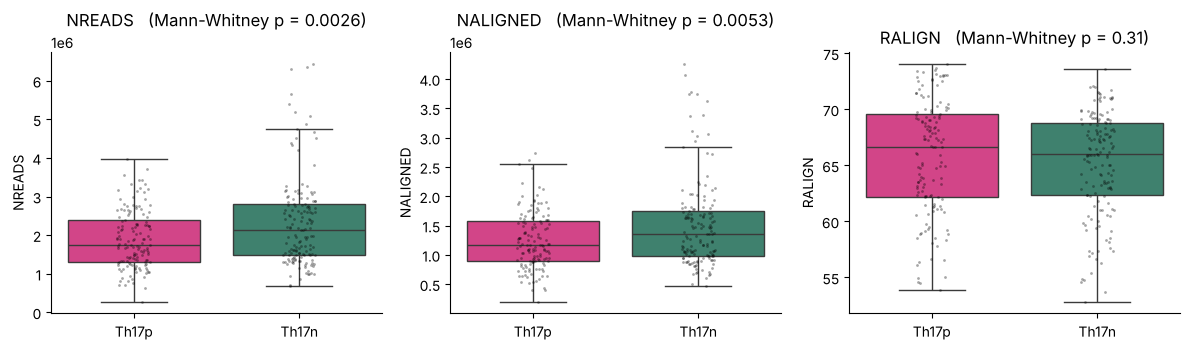

Median per group:
              NREADS   NALIGNED  RALIGN
cell_type                              
Th17p      1746220.0  1164730.0    66.6
Th17n      2123860.0  1350270.0    66.0

Th17p cells have 18% fewer reads than Th17n cells (median ratio 0.82).


In [3]:
qc_cols = ["NREADS", "NALIGNED", "RALIGN"]
order = ["Th17p", "Th17n"]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, col in zip(axes, qc_cols):
    sns.boxplot(data=meta, x="cell_type", y=col, order=order, hue="cell_type", palette=PAL, legend=False, fliersize=0, ax=ax)
    sns.stripplot(data=meta, x="cell_type", y=col, order=order, color="k", size=2, alpha=.35, ax=ax)
    p = stats.mannwhitneyu(meta.loc[cells_p, col], meta.loc[cells_n, col]).pvalue
    ax.set_title(f"{col}   (Mann-Whitney p = {p:.2g})"); ax.set_xlabel("")
plt.tight_layout(); plt.show()
print("Median per group:")
print(meta.groupby("cell_type")[qc_cols].median().round(1).loc[order])
depth_ratio = meta.loc[cells_p, "NREADS"].median() / meta.loc[cells_n, "NREADS"].median()
print(f"\nTh17p cells have {1 - depth_ratio:.0%} fewer reads than Th17n cells (median ratio {depth_ratio:.2f}).")

**How to read it.** Each panel compares one technical measurement between the two groups (box = middle 50 % of cells, line = median, dots = cells). The title gives the Mann–Whitney p-value: a small p means the groups differ in that measurement.

**What you should see.** Th17p cells were sequenced less deeply than Th17n cells: about 18 % fewer reads (median 1.75 M vs 2.12 M; p ≈ 0.003) and fewer aligned reads (p ≈ 0.005), while the *alignment rate* is the same (≈ 66 %, p ≈ 0.3). So the two groups differ in **depth** but not in read quality.

**Why it matters / what it does not mean [Inference].** A depth difference does not by itself invalidate the paper — the pipeline works on TPM, which rescales each cell, and the paper normalises batch/nuisance factors with SCONE **[Paper, "Estimation of transcript abundance"]**; the QC columns shipped with the repo are *pre*-normalisation counts, so they cannot tell us how much depth effect is left. It is, however, the first technical variable to keep as a covariate / sensitivity check later (§3.2 shows depth does drive how many genes are detected; §6.4 shows that the *overall level* of the Compass scores follows gene detection).

### 3.2 The expression matrix: scale, sparsity, dropout
Smart-seq data are deep (≈2 M reads/cell) but still sparse: many genes read 0 in a given cell ("dropout"). This matters because Compass builds penalties from expression — a zero becomes the *maximum* penalty for that gene. The paper motivates the kNN smoothing as a remedy for "sparseness and stochasticity of single-cell measurements" **[Paper, "Information sharing between single cells"]**.

zeros overall           : 33.6% of all matrix entries
genes detected per cell : median 5,972  (min 4,286, max 6,692)
sum of TPM per cell     : median 923,234
genes detected in ALL 290 cells: 890 of 8,813


Spearman(genes detected, NREADS) = 0.33;  Spearman(genes detected, alignment rate) = -0.00
genes detected per cell: Th17p median 6,018 vs Th17n 5,943 (MWU p = 0.2)


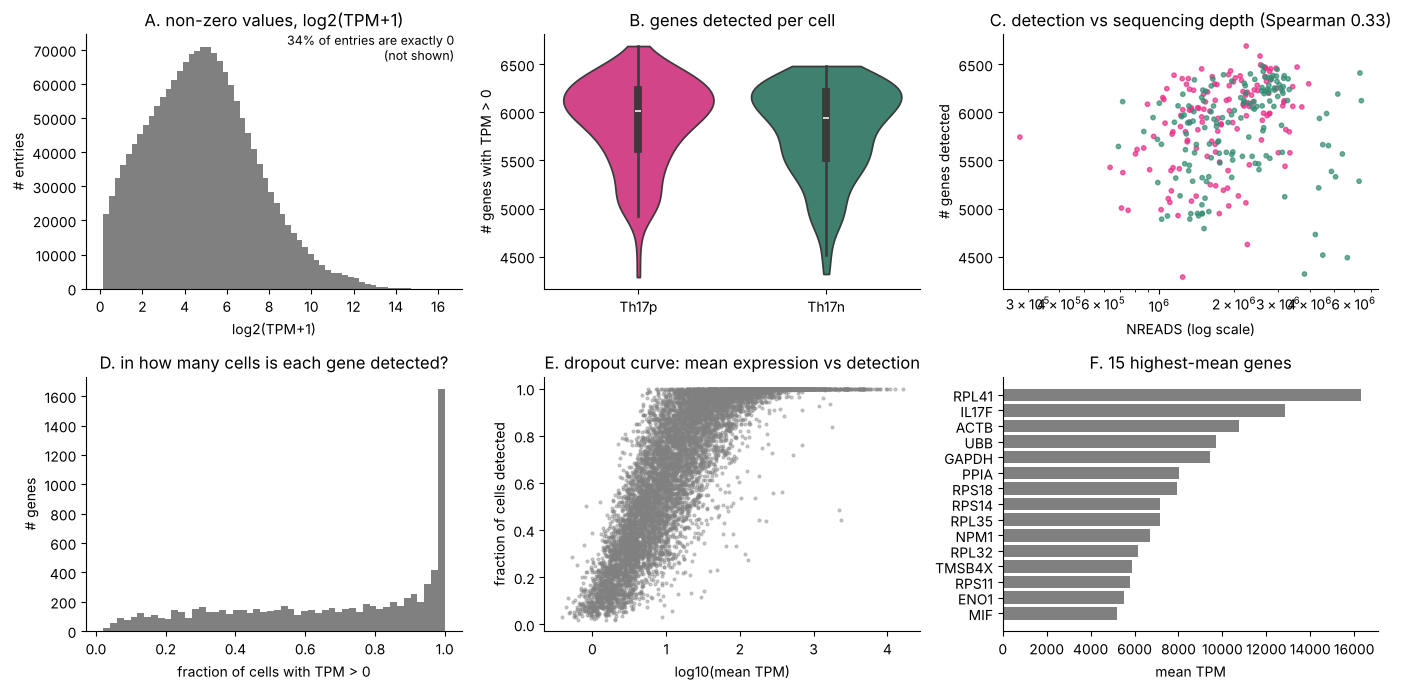

In [4]:
n_detected = (expr > 0).sum()              # genes with TPM > 0, per cell
lib_size   = expr.sum()                    # sum of TPM per cell (not exactly 1e6: the repo copy is gene-filtered)
gene_det   = (expr > 0).mean(axis=1)       # fraction of cells in which each gene is detected
gene_mean  = expr.mean(axis=1)

print(f"zeros overall           : {(expr.values == 0).mean():.1%} of all matrix entries")
print(f"genes detected per cell : median {n_detected.median():,.0f}  (min {n_detected.min():,}, max {n_detected.max():,})")
print(f"sum of TPM per cell     : median {lib_size.median():,.0f}")
print(f"genes detected in ALL 290 cells: {(gene_det == 1).sum():,} of {len(gene_det):,}")

fig, ax = plt.subplots(2, 3, figsize=(14, 7))
a = ax[0, 0]; a.hist(np.log2(expr.values[expr.values > 0] + 1), bins=60, color="grey")
a.set_title("A. non-zero values, log2(TPM+1)"); a.set_xlabel("log2(TPM+1)"); a.set_ylabel("# entries")
a.text(.98, .9, f"{(expr.values == 0).mean():.0%} of entries are exactly 0\n(not shown)", transform=a.transAxes, ha="right", fontsize=9)

a = ax[0, 1]; sns.violinplot(x=meta.cell_type, y=n_detected, order=order, hue=meta.cell_type, palette=PAL, legend=False, ax=a, cut=0)
a.set_title("B. genes detected per cell"); a.set_xlabel(""); a.set_ylabel("# genes with TPM > 0")

a = ax[0, 2]; a.scatter(meta.NREADS, n_detected, c=meta.cell_type.map(PAL), s=10, alpha=.7); a.set_xscale("log")
rho = stats.spearmanr(meta.NREADS, n_detected)[0]; rho_al = stats.spearmanr(meta.RALIGN, n_detected)[0]
a.set_title(f"C. detection vs sequencing depth (Spearman {rho:.2f})"); a.set_xlabel("NREADS (log scale)"); a.set_ylabel("# genes detected")
print(f"Spearman(genes detected, NREADS) = {rho:.2f};  Spearman(genes detected, alignment rate) = {rho_al:.2f}")
p_det = stats.mannwhitneyu(n_detected[cells_p], n_detected[cells_n]).pvalue
print(f"genes detected per cell: Th17p median {n_detected[cells_p].median():,.0f} vs Th17n {n_detected[cells_n].median():,.0f} (MWU p = {p_det:.2g})")

a = ax[1, 0]; a.hist(gene_det, bins=50, color="grey")
a.set_title("D. in how many cells is each gene detected?"); a.set_xlabel("fraction of cells with TPM > 0"); a.set_ylabel("# genes")

a = ax[1, 1]; a.scatter(np.log10(gene_mean + 1e-3), gene_det, s=4, alpha=.4, color="grey")
a.set_title("E. dropout curve: mean expression vs detection"); a.set_xlabel("log10(mean TPM)"); a.set_ylabel("fraction of cells detected")

a = ax[1, 2]; top = gene_mean.sort_values(ascending=False).head(15)[::-1]
a.barh(top.index, top.values, color="grey"); a.set_title("F. 15 highest-mean genes"); a.set_xlabel("mean TPM")
plt.tight_layout(); plt.show()

**How to read it.**
* **A** – the matrix is mostly zeros plus a roughly log-normal bulk. **E** – low-mean genes are detected in few cells: for them, "expression = 0" often means *not captured*, not *not made*. That is the reason Compass shares information between similar cells.
* **B/C** – B asks whether the groups differ in how many genes they yield (here: no clear difference, p ≈ 0.2, medians ≈ 6,000). C asks *why a cell yields more or fewer genes*: it rises with sequencing depth (Spearman ≈ 0.33) and is unrelated to the alignment rate (≈ 0). So cell-to-cell differences in "number of genes detected" are partly technical, and any downstream score that is sensitive to the gene count inherits that **[Inference]** — §6.4 tests exactly this for the Compass scores.
* **F** – sanity check: the top genes should be housekeeping/ribosomal/cytoskeletal, which they are if the file loaded correctly.

### 3.3 Do the group labels behave as the paper says? — the pathogenicity signature
Before trusting any Th17p-vs-Th17n *metabolic* result we confirm that the two labels differ in the expected *transcriptional* way. The paper defines a per-cell pathogenicity score: the average z-scored expression (log(1+TPM)) of **15 pro-pathogenic** markers and **7 pro-regulatory** markers, the latter multiplied by −1 **[Paper, STAR Methods "Th17 pathogenicity"]**. (z-scoring makes the log base irrelevant.)

pathogenicity score: Th17p mean +0.34  vs  Th17n mean -0.31
AUC (probability a random Th17p cell scores above a random Th17n cell) = 0.969
markers moving in the direction the paper labels them: 20 / 22   (exceptions: LGALS3, IL1RN)


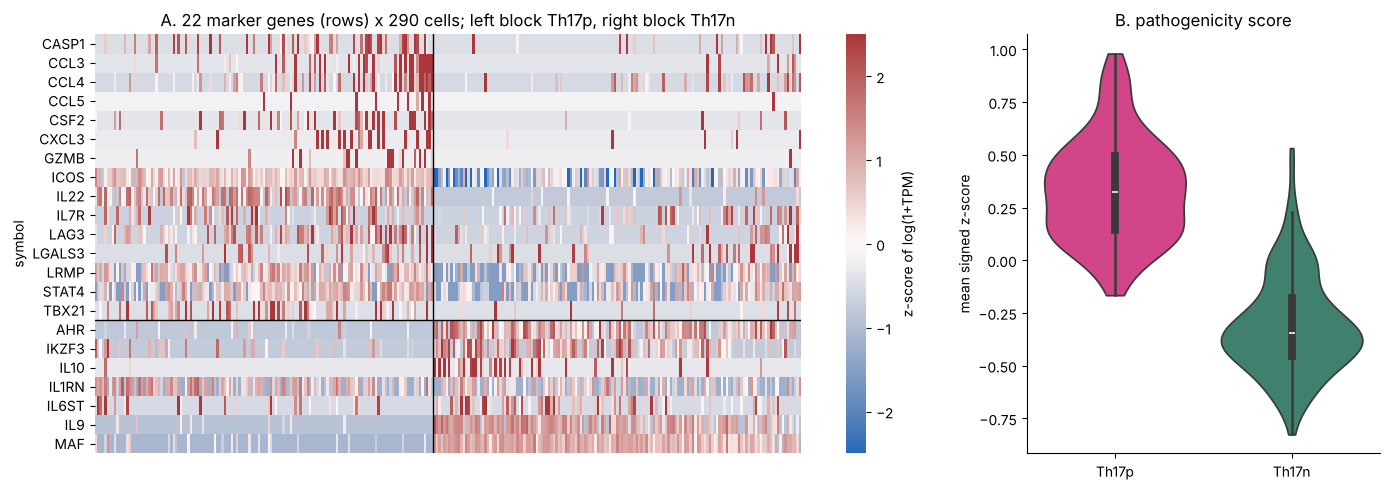

In [5]:
PRO_PATHOGENIC = ["CASP1","CCL3","CCL4","CCL5","CSF2","CXCL3","GZMB","ICOS","IL22","IL7R","LAG3","LGALS3","LRMP","STAT4","TBX21"]
PRO_REGULATORY = ["AHR","IKZF3","IL10","IL1RN","IL6ST","IL9","MAF"]
markers = PRO_PATHOGENIC + PRO_REGULATORY
assert all(g in expr.index for g in markers), "a marker gene is missing from the matrix"

log_tpm = np.log1p(expr)                                                     # log(1 + TPM)   [Paper]
z = log_tpm.loc[markers].sub(log_tpm.loc[markers].mean(axis=1), axis=0).div(log_tpm.loc[markers].std(axis=1), axis=0)
signed = pd.concat([z.loc[PRO_PATHOGENIC], -1 * z.loc[PRO_REGULATORY]])      # pro-regulatory multiplied by -1
pathogenicity = signed.mean()                                               # one number per cell

U = stats.mannwhitneyu(pathogenicity[cells_p], pathogenicity[cells_n]).statistic
print(f"pathogenicity score: Th17p mean {pathogenicity[cells_p].mean():+.2f}  vs  Th17n mean {pathogenicity[cells_n].mean():+.2f}")
print(f"AUC (probability a random Th17p cell scores above a random Th17n cell) = {U/(len(cells_p)*len(cells_n)):.3f}")

# per-gene direction check: pro-pathogenic genes should be higher in Th17p, pro-regulatory lower
d_gene = (log_tpm.loc[markers, cells_p].mean(axis=1) - log_tpm.loc[markers, cells_n].mean(axis=1))
expected = pd.Series([1]*len(PRO_PATHOGENIC) + [-1]*len(PRO_REGULATORY), index=markers)
agree = (np.sign(d_gene) == expected)
print(f"markers moving in the direction the paper labels them: {agree.sum()} / {len(markers)}   (exceptions: {', '.join(agree.index[~agree]) or 'none'})")

col_order = list(pathogenicity[cells_p].sort_values().index) + list(pathogenicity[cells_n].sort_values().index)
fig, ax = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [3, 1.2]})
sns.heatmap(z[col_order], cmap="vlag", center=0, vmin=-2.5, vmax=2.5, xticklabels=False, ax=ax[0], cbar_kws={"label": "z-score of log(1+TPM)"})
ax[0].axvline(len(cells_p), color="k", lw=1); ax[0].set_title("A. 22 marker genes (rows) x 290 cells; left block Th17p, right block Th17n")
ax[0].axhline(len(PRO_PATHOGENIC), color="k", lw=1)
sns.violinplot(x=meta.cell_type, y=pathogenicity, order=order, hue=meta.cell_type, palette=PAL, legend=False, cut=0, ax=ax[1])
ax[1].set_title("B. pathogenicity score"); ax[1].set_xlabel(""); ax[1].set_ylabel("mean signed z-score")
plt.tight_layout(); plt.show()

**How to read it.** In A, the top 15 rows (pro-pathogenic) should be red on the left (Th17p) and the bottom 7 rows (pro-regulatory) red on the right (Th17n). B condenses that into one number per cell; the **AUC** is the probability that a random Th17p cell has a higher score than a random Th17n cell (0.5 = no separation, 1 = perfect). The score also overlaps between groups — Th17p/Th17n are *extremes of a continuum*, which is why the paper later correlates reactions with the continuous score as well **[Paper, Fig. 2D / 4A]**.

### 3.4 Cell-state structure — the neighbourhood Compass smooths over
Compass computes a kNN graph on the **top 20 principal components of log2(expression+1) over all genes** (not just metabolic ones), k = 10, and mixes each cell's reaction expression with the average of its neighbours' (weight λ = 0.25) **[Paper, "Information sharing between single cells"; Repo penalties.py]**. We rebuild exactly that graph.

mean fraction of a cell's 10 neighbours from its own group: 0.99   (random expectation 0.50)
cells whose 10 neighbours are ALL from their own group: 92%


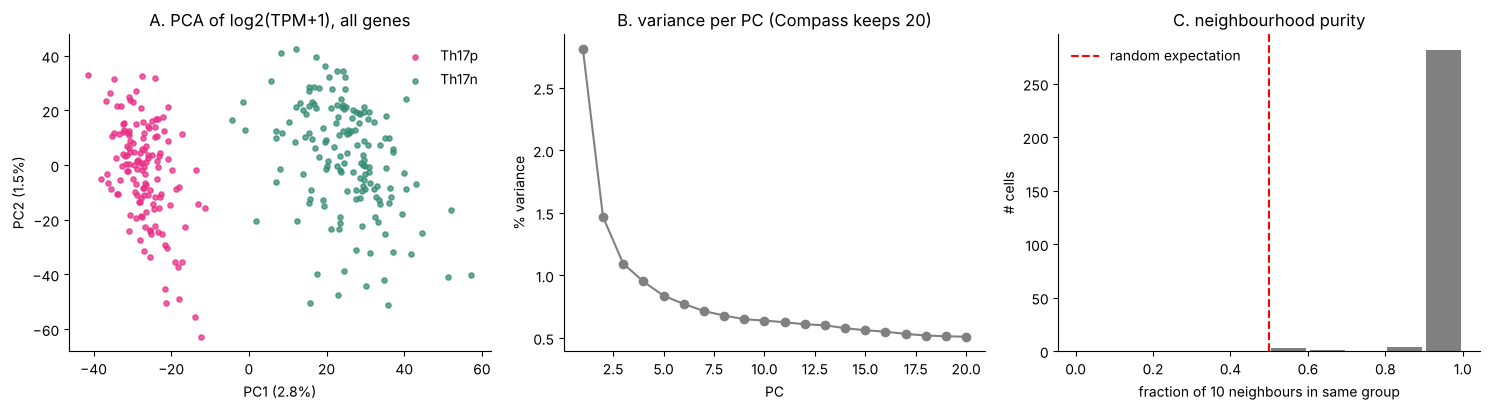

In [6]:
log2x = np.log2(expr + 1)
pca_expr = PCA(n_components=20, random_state=PCA_SEED)                      # [Repo penalties.py] PCA on all genes, 20 comps
emb = pca_expr.fit_transform(log2x.T.to_numpy())                            # cells x 20
nbrs = NearestNeighbors(n_neighbors=KNN_K).fit(emb)
knn_idx = nbrs.kneighbors(return_distance=False)                            # neighbours EXCLUDING the cell itself

labels = meta.cell_type.to_numpy()
same_group = (labels[knn_idx] == labels[:, None]).mean(axis=1)              # fraction of the 10 neighbours with the same label
baseline = pd.Series(labels).map({"Th17p": (len(cells_p)-1)/(len(labels)-1), "Th17n": (len(cells_n)-1)/(len(labels)-1)}).to_numpy()
print(f"mean fraction of a cell's {KNN_K} neighbours from its own group: {same_group.mean():.2f}   (random expectation {baseline.mean():.2f})")
print(f"cells whose 10 neighbours are ALL from their own group: {(same_group == 1).mean():.0%}")

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for g, c in PAL.items():
    m = labels == g; ax[0].scatter(emb[m, 0], emb[m, 1], s=14, color=c, alpha=.75, label=g)
ax[0].set_xlabel(f"PC1 ({pca_expr.explained_variance_ratio_[0]:.1%})"); ax[0].set_ylabel(f"PC2 ({pca_expr.explained_variance_ratio_[1]:.1%})")
ax[0].set_title("A. PCA of log2(TPM+1), all genes"); ax[0].legend(frameon=False)
ax[1].plot(range(1, 21), pca_expr.explained_variance_ratio_ * 100, "o-", color="grey"); ax[1].set_xlabel("PC"); ax[1].set_ylabel("% variance")
ax[1].set_title("B. variance per PC (Compass keeps 20)")
ax[2].hist(same_group, bins=np.linspace(0, 1, 11), color="grey", rwidth=.9); ax[2].axvline(baseline.mean(), color="r", ls="--", label="random expectation")
ax[2].set_xlabel("fraction of 10 neighbours in same group"); ax[2].set_ylabel("# cells"); ax[2].set_title("C. neighbourhood purity"); ax[2].legend(frameon=False)
plt.tight_layout(); plt.show()

**How to read it.** Panel A shows that the two conditions are already almost perfectly separable on the first expression PC (a strong, clean contrast). Panel C: if neighbourhoods are far purer than the random expectation (here ≈ 0.99 vs 0.50 — essentially *every* neighbourhood contains a single condition), smoothing averages a cell with cells *of the same condition*: good for denoising, and it cannot wash out the Th17p/Th17n contrast. The flip side **[Inference]**: neighbours now share information, so the 290 smoothed cells are *less* independent than 290 raw cells, which inflates the significance of cell-level tests in §6.

### 3.5 How much of the transcriptome is "metabolic"? (Recon2 gene coverage)
Compass can only use genes that appear in Recon2's gene–reaction rules. `gene_metadata.csv` lists them with human and mouse symbols; the mouse symbols come from MGI HomoloGene orthologs, and genes without a mouse ortholog are blank **[Repo, geneSymbols.py / gene_metadata.csv]**.

We also compute the paper's **total metabolic activity** of a cell: the sum of expression of metabolic-enzyme genes over the sum of expression of all protein-coding genes, in log-scale TPM **[Paper, STAR Methods "Total metabolic activity of a cell"]**. **[Inference]** The repo matrix has no biotype column, so the denominator below is *all genes in the matrix* (a proxy for protein-coding genes).

Recon2 genes with a mouse symbol : 1,638 (of 1,733 Recon2 gene rows; 46 have no mouse ortholog)
... present in this expression matrix: 895   -> 10.2% of the 8,813 genes in the matrix
... detected (TPM>0) in at least one cell: 895
total metabolic activity: Th17p median 0.1123 vs Th17n median 0.1120 (MWU p = 0.098)


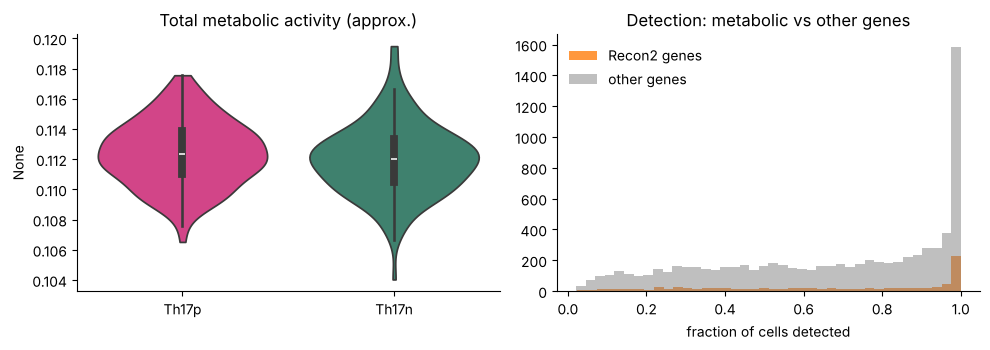

In [7]:
metab_symbols = set(gene_md["MGI.symbol"].dropna().str.upper())
in_data  = [g for g in metab_symbols if g in expr.index]
detected = [g for g in in_data if gene_det[g] > 0]
print(f"Recon2 genes with a mouse symbol : {len(metab_symbols):,} (of {len(gene_md):,} Recon2 gene rows; {gene_md['MGI.symbol'].isna().sum()} have no mouse ortholog)")
print(f"... present in this expression matrix: {len(in_data):,}   -> {len(in_data)/len(expr):.1%} of the {len(expr):,} genes in the matrix")
print(f"... detected (TPM>0) in at least one cell: {len(detected):,}")

is_metab = expr.index.isin(metab_symbols)
tma = log2x[is_metab].sum() / log2x.sum()                    # total metabolic activity (approx., see note above)
denominator = log2x.sum()                                     # covariate the paper controls for
p_tma = stats.mannwhitneyu(tma[cells_p], tma[cells_n]).pvalue
print(f"total metabolic activity: Th17p median {tma[cells_p].median():.4f} vs Th17n median {tma[cells_n].median():.4f} (MWU p = {p_tma:.2g})")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
sns.violinplot(x=meta.cell_type, y=tma, order=order, hue=meta.cell_type, palette=PAL, legend=False, cut=0, ax=ax[0]); ax[0].set_title("Total metabolic activity (approx.)"); ax[0].set_xlabel("")
ax[1].hist(gene_det[is_metab], bins=40, color="tab:orange", alpha=.8, label="Recon2 genes"); ax[1].hist(gene_det[~is_metab], bins=40, color="grey", alpha=.5, label="other genes")
ax[1].set_xlabel("fraction of cells detected"); ax[1].set_title("Detection: metabolic vs other genes"); ax[1].legend(frameon=False)
plt.tight_layout(); plt.show()

## 4 · The Recon2 network as a table (`reaction_metadata.csv`)
Recon2 is the genome-scale metabolic model (GSMM) Compass uses: **7,440 reactions, 2,626 unique metabolites** **[Paper, Results]**. Each reaction has a gene rule (which enzymes catalyse it), a subsystem (pathway label), an EC number, and a **confidence score** between 1 (no evidence) and 4 (biochemical evidence); 0 = not evaluated **[Paper, "Core metabolic reactions and meta-reactions"]**.

**Core metabolism** (paper definition): confidence ∈ {0, 4} **and** an annotated EC number. **Core pathways:** subsystems with ≥ 3 core reactions. A meta-reaction is core if it contains ≥ 1 core reaction **[Paper, same section]**.

reactions in Recon2 table      : 7,440   (paper: 7,440)
unique metabolites (no compart.): 2,626   (paper: 2,626)
reactions WITH a gene rule     : 4,740  (64%);  WITHOUT: 2,700
core reactions                 : 2,598   in 76 core pathways (>=3 core reactions)


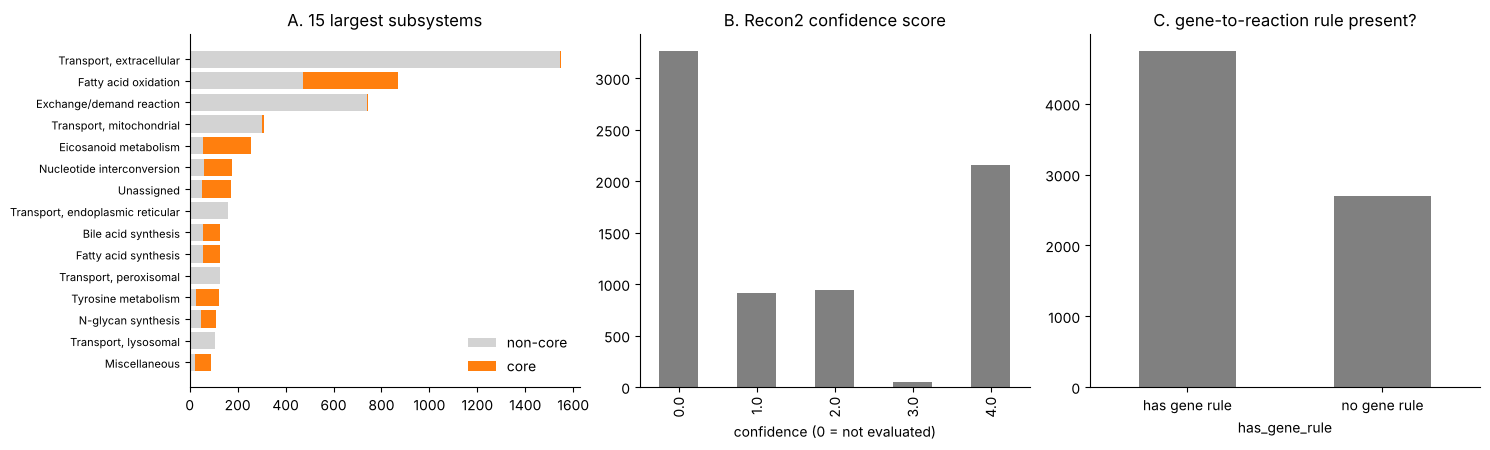

,reaction_name,associated_genes,subsystem,EC_number,confidence
reaction_no_direction,,,,,
PGM,phosphoglycerate mutase,BPGM; PGAM1; PGAM2,Glycolysis/gluconeogenesis,5.4.2.1,0.0
LDH_L,L-lactate dehydrogenase,LDHA; LDHAL6B; LDHB; LDHC; UEVLD,Glycolysis/gluconeogenesis,1.1.1.27,0.0
PDHm,pyruvate dehydrogenase,DLAT; DLD; PDHA1; PDHA2; PDHB; PDHX,Glycolysis/gluconeogenesis,2.3.1.12,0.0


In [8]:
rxn_md["has_gene_rule"] = rxn_md["associated_genes"].notna()
rxn_md["is_core"]       = rxn_md["confidence"].isin([0, 4]) & rxn_md["EC_number"].notna()
core_pathways = rxn_md.loc[rxn_md.is_core, "subsystem"].value_counts()
core_pathways = core_pathways[core_pathways >= 3].index

print(f"reactions in Recon2 table      : {len(rxn_md):,}   (paper: 7,440)")
print(f"unique metabolites (no compart.): {met_md['metabolite_no_compartment'].nunique():,}   (paper: 2,626)")
print(f"reactions WITH a gene rule     : {rxn_md.has_gene_rule.sum():,}  ({rxn_md.has_gene_rule.mean():.0%});  WITHOUT: {(~rxn_md.has_gene_rule).sum():,}")
print(f"core reactions                 : {rxn_md.is_core.sum():,}   in {len(core_pathways)} core pathways (>=3 core reactions)")

fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
top = rxn_md.groupby("subsystem").agg(n=("is_core", "size"), core=("is_core", "sum")).sort_values("n", ascending=False).head(15)[::-1]
ax[0].barh(top.index, top.n - top.core, color="lightgrey", label="non-core"); ax[0].barh(top.index, top.core, left=top.n - top.core, color="tab:orange", label="core")
ax[0].set_title("A. 15 largest subsystems"); ax[0].legend(frameon=False); ax[0].tick_params(axis="y", labelsize=8)
rxn_md.confidence.value_counts().sort_index().plot.bar(ax=ax[1], color="grey"); ax[1].set_title("B. Recon2 confidence score"); ax[1].set_xlabel("confidence (0 = not evaluated)")
rxn_md.has_gene_rule.value_counts().rename({True: "has gene rule", False: "no gene rule"}).plot.bar(ax=ax[2], color="grey", rot=0); ax[2].set_title("C. gene-to-reaction rule present?")
plt.tight_layout(); plt.show()
rxn_md.loc[["PGM", "LDH_L", "PDHm"], ["reaction_name", "associated_genes", "subsystem", "EC_number", "confidence"]]

**How to read it.** C is a key limitation to remember: reactions *without* a gene rule (transporters, exchange/demand reactions, spontaneous reactions…) cannot receive expression-based penalties. In stage 1 Compass assigns them reaction-expression 0, i.e. the **maximum penalty (1.0)**; their final score then reflects only the surrounding network **[Repo, penalties.py / MetabolicModel.py; verified in Notebook 2]**. Look at the PDH row: its gene rule contains six genes (a complex) — how those are combined (mean for AND, sum for OR) is the subject of Notebook 2.

Also note the reaction ids: the Compass output has `_pos`/`_neg` suffixes (e.g. `PGM_neg`) because **every reversible reaction is split into a forward and a backward unidirectional reaction** **[Paper, Alg. 1–2; Repo MetabolicModel.make_unidirectional]**. The metadata table has no suffix.

## 5 · What the Compass output (`reactions.tsv`) actually contains
Each entry is the **minimum total penalty** of a flux distribution that carries ≥ 95 % of reaction *r*'s maximal flux, for cell *c* **[Paper, Alg. 2]**. High penalty = the cell's transcriptome gives *little* support for using that reaction; the paper then negates/scales it into a "potential activity" score **[Paper, Alg. 3]**:

* `score = −log(1 + penalty)`, then subtract the matrix-wide minimum so every score ≥ 0
* drop reactions whose score range across cells is < 10⁻³ ("constant rows")

Below: what is in the raw file, and what the transform removes.

kept for analysis                      6381
blocked (penalty = 0 in all cells)     3414
near-constant (score range < 0.001)     416

any zero entries in a row that is not all-zero? 0
non-zero penalties: median 3,212, 5th-95th percentile 7 - 39,550


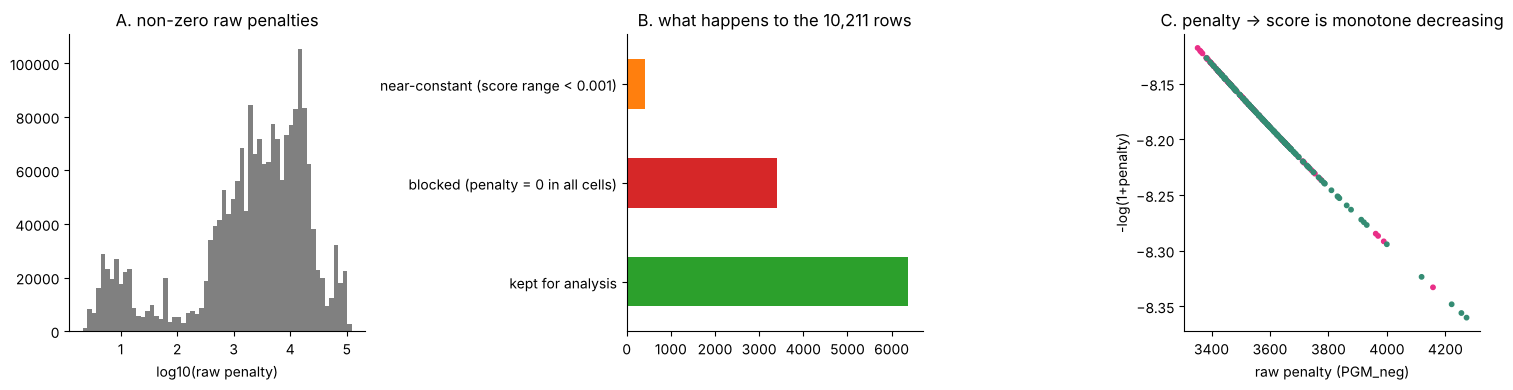

In [9]:
is_blocked = (pen == 0).all(axis=1)                              # exactly zero in every cell
score_raw  = -np.log(pen + 1)
score_rng  = score_raw.max(axis=1) - score_raw.min(axis=1)
status = pd.Series(np.select([is_blocked, score_rng < MIN_RANGE], ["blocked (penalty = 0 in all cells)", f"near-constant (score range < {MIN_RANGE:g})"], "kept for analysis"), index=pen.index)
print(status.value_counts().to_string())
print(f"\nany zero entries in a row that is not all-zero? {((pen == 0).any(axis=1) & ~is_blocked).sum()}")
nz = pen.values[pen.values > 0]
print(f"non-zero penalties: median {np.median(nz):,.0f}, 5th-95th percentile {np.percentile(nz,5):,.0f} - {np.percentile(nz,95):,.0f}")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(np.log10(nz), bins=60, color="grey"); ax[0].set_xlabel("log10(raw penalty)"); ax[0].set_title("A. non-zero raw penalties")
status.value_counts().plot.barh(ax=ax[1], color=["tab:green", "tab:red", "tab:orange"][:status.nunique()]); ax[1].set_title("B. what happens to the 10,211 rows")
r = "PGM_neg"
ax[2].scatter(pen.loc[r], -np.log(pen.loc[r] + 1), c=meta.cell_type.map(PAL), s=10)
ax[2].set_xlabel(f"raw penalty ({r})"); ax[2].set_ylabel("-log(1+penalty)"); ax[2].set_title("C. penalty -> score is monotone decreasing")
plt.tight_layout(); plt.show()

**How to read it.**
* **Blocked rows** are reactions whose maximal flux v^opt is 0 in the default medium, so Compass skips them and writes 0 **[Repo, algorithm.py `compass_reactions`: "If Reaction can't carry flux anyways … reaction_scores[reaction.id] = 0"]**. They carry no information. (Notebook 2 shows the count equals the number of v^opt = 0 entries in the shipped cache.)
* **Typical penalties are in the thousands**, not ~1: the LP requires ≥ 0.95 × v^opt (v^opt is up to 1000) of flux, so the *absolute* penalty is dominated by that large forced flux times per-reaction penalties of ~0.1–1. Only the *differences between cells, for one reaction at a time* carry information: the repo's quickstart states that "reaction scores are only comparable across different samples for a given reaction" and that one should not compare scores between reactions within a sample **[Repo, docs/quickstart.rst]**; Notebook 2 shows numerically *why* the absolute size is arbitrary. (Rank tests are unchanged by any monotone rescaling and Cohen's d by any linear rescaling of a reaction's scores, so the paper's statistics are insensitive to that arbitrary scale.)
* **C** – the transform is a pure monotone relabelling: ranks (hence Wilcoxon tests) are unchanged by `−log(1+·)`, but Cohen's d and PCA are not.

## 6 · Five preliminary figures (replicating early parts of the paper)
We reproduce, from the repo's precomputed output: **(S1A)** meta-reaction sizes, **(2B)** PCA of the Compass space, **(S2C)** PC1 vs total metabolic activity, **(2C)** per-pathway volcano plots, **(2E)** Cohen's d by subsystem. First the (short, readable) functions — each one mirrors a paper/repo definition.

Section **6.2b** then adds a **sensitivity analysis**: how much do the paper's thresholds (meta-reaction merging rho = 0.98, the constant-row filter, the significance level) change the counts, compared with the paper's own numbers - with histograms.

In [10]:
def cohens_d_rows(A, B):
    """Cohen's d per row = (mean_A - mean_B) / pooled SD.   [Paper STAR Methods; Repo compass_analysis.cohens_d]"""
    nA, nB = A.shape[1], B.shape[1]
    pooled = np.sqrt(((nA - 1) * A.var(axis=1, ddof=1) + (nB - 1) * B.var(axis=1, ddof=1)) / (nA + nB - 2))
    with np.errstate(divide="ignore", invalid="ignore"):
        return (A.mean(axis=1) - B.mean(axis=1)) / pooled

def benjamini_hochberg(p):
    """Benjamini-Hochberg adjusted p-values (FDR).  [Paper: 'adjusted p'; same numbers as statsmodels multipletests(method="fdr_bh")]
       1) sort the m p-values ascending; 2) adjusted(i) = p(i) * m / i  (i = rank);
       3) go from the largest rank down and keep the running minimum (so adjusted values never decrease with p); 4) cap at 1."""
    p = np.asarray(p, float)
    m = len(p)
    order = np.argsort(p)
    scaled = p[order] * m / np.arange(1, m + 1)
    adj_sorted = np.minimum.accumulate(scaled[::-1])[::-1]
    adj = np.empty(m)
    adj[order] = np.clip(adj_sorted, 0, 1)
    return adj

def differential_activity(scores, cells_a, cells_b):
    """Wilcoxon rank-sum (Mann-Whitney, two-sided) + Cohen's d + Benjamini-Hochberg, one row per reaction.
       Positive d  =>  higher potential activity in group A.   [Paper 'Finding reactions with differential potential activity']"""
    A, B = scores[cells_a].to_numpy(float), scores[cells_b].to_numpy(float)
    res = stats.mannwhitneyu(A, B, axis=1, alternative="two-sided")
    p = np.where(np.isnan(res.pvalue), 1.0, res.pvalue)               # constant rows -> p = 1 (as in the repo)
    out = pd.DataFrame({"U": res.statistic, "p": p, "cohens_d": cohens_d_rows(A, B)}, index=scores.index)
    out["adj_p"] = benjamini_hochberg(out["p"])
    return out

def penalties_to_scores(penalties, min_range=MIN_RANGE):
    """Alg. 3: score = -log(1+penalty); drop near-constant rows; shift by the global minimum.   [Repo get_reaction_consistencies]"""
    s = -np.log(penalties + 1)
    s = s[(s.max(axis=1) - s.min(axis=1)) >= min_range]
    return s - s.min().min()

def make_meta_reactions(penalties, zero_cutoff=ZERO_CUTOFF, height=CLUSTER_HEIGHT):
    """Group reactions whose penalties are almost perfectly rank-correlated across cells.
       Spearman distance 1-rho, complete linkage, cut at `height` (rho >= 0.98), then average the member rows.
       [Paper 'Meta-reactions'; Repo postprocessing.ipynb + compass_analysis.get_metareactions]"""
    p = penalties.mask(penalties <= zero_cutoff, 0.0)
    p = p[(p != 0).all(axis=1)]                                   # drop reactions that are 0 in any cell (blocked)
    p = p[(p.max(axis=1) - p.min(axis=1)) != 0]                   # drop exactly-constant rows
    rho = np.corrcoef(p.rank(axis=1).to_numpy())                  # Spearman = Pearson on within-row ranks
    np.fill_diagonal(rho, 1.0); rho = (rho + rho.T) / 2
    Z = linkage(squareform(1 - rho, checks=False), method="complete")
    lab = pd.Series(fcluster(Z, t=height, criterion="distance"), index=p.index, name="meta")
    return lab, p.groupby(lab).mean()

def base_id(r):
    """'PGM_neg' -> 'PGM' (the Recon2 metadata table has no direction suffix)"""
    return r[:-4] if r.endswith(("_pos", "_neg")) else r

### 6.0 Sanity check: do my functions agree with the repo's own helper module?
If the repo's `compass_analysis.py` can be imported (it imports `statsmodels`; if that package is not installed this optional check is skipped automatically and nothing else is affected), compare results on 300 reactions. A mismatch here would mean *my* code, not the paper, is wrong.

In [11]:
sys.path.insert(0, str(REPO / "docs/notebooks"))
try:
    import compass_analysis as ca
    s_mine = penalties_to_scores(pen); s_repo = ca.get_reaction_consistencies(pen)
    sub = s_mine.index[:300]
    r_mine = differential_activity(s_mine.loc[sub], cells_p, cells_n)
    r_repo = ca.wilcoxon_test(s_repo.loc[sub], cells_p, cells_n)
    print("scores identical to repo     :", np.allclose(s_mine.values, s_repo.values))
    print("p-values identical           :", np.allclose(r_mine.p, r_repo.wilcox_pval, equal_nan=True))
    print("Cohen's d identical          :", np.allclose(r_mine.cohens_d, r_repo.cohens_d, equal_nan=True, atol=1e-10))
    # meta-reaction grouping is checked on the full set in section 6.1
except Exception as e:
    print("repo helper not importable here -> skipping the cross-check:", type(e).__name__, e)

scores identical to repo     : True
p-values identical           : True
Cohen's d identical          : True


### 6.1 Figure S1A — how many reactions end up in a meta-reaction?
**What the paper does.** Reactions that sit next to each other in the network have almost perfectly correlated scores, so they are merged ("meta-reactions": Spearman ρ ≥ 0.98, complete linkage; row-average). The paper reports a **median of two reactions per meta-reaction** and **1,911 meta-reactions** **[Paper, Results & Figure S1A; STAR Methods]**.
**Why it matters.** All downstream stats are computed on meta-reactions and then copied to every member reaction — so the number of *independent* tests is ≈ 1.9 k, not 6.5 k, and it is **dataset-dependent** **[Paper, "Meta-reactions"]**.

**Added:** panel A is now a **histogram** of the meta-reaction sizes (how many meta-reactions have 1, 2, 3, ... member reactions); panel B is the cumulative version shown before. A histogram answers "what is typical?", the cumulative curve answers "what fraction is at most this big?".

reactions clustered: 6,385  ->  1,709 meta-reactions   (paper: 1,911)
reactions per meta-reaction: median 2 (paper: 2), mean 3.7, max 155, singletons 40%


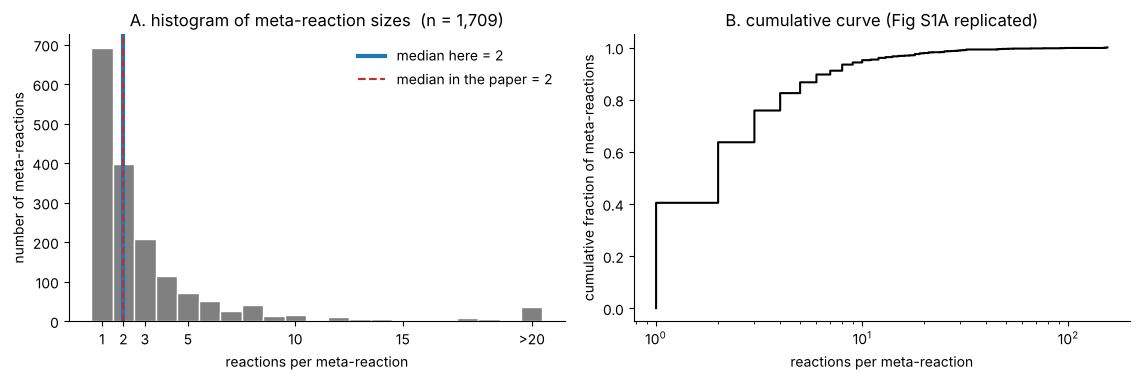

In [12]:
labels_meta, meta_pen = make_meta_reactions(pen)                 # reaction -> meta-reaction id, and averaged penalties
sizes = labels_meta.value_counts()
print(f"reactions clustered: {len(labels_meta):,}  ->  {len(sizes):,} meta-reactions   (paper: 1,911)")
print(f"reactions per meta-reaction: median {sizes.median():.0f} (paper: 2), mean {sizes.mean():.1f}, max {sizes.max()}, singletons {(sizes == 1).mean():.0%}")

fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.9))
# A. histogram: how many meta-reactions have 1, 2, 3, ... member reactions? (sizes above 20 are lumped into the last bar)
ax[0].hist(np.minimum(sizes.values, 21), bins=np.arange(0.5, 22.5, 1), color="grey", edgecolor="white")
ax[0].axvline(sizes.median(), color="tab:blue", lw=3, label=f"median here = {sizes.median():.0f}")
ax[0].axvline(2, color="tab:red", ls="--", lw=1.5, label="median in the paper = 2")
ax[0].set_xticks([1, 2, 3, 5, 10, 15, 21]); ax[0].set_xticklabels(["1", "2", "3", "5", "10", "15", ">20"])
ax[0].set_xlabel("reactions per meta-reaction"); ax[0].set_ylabel("number of meta-reactions")
ax[0].set_title(f"A. histogram of meta-reaction sizes  (n = {len(sizes):,})"); ax[0].legend(frameon=False)
# B. the same information as a cumulative curve
xs = np.sort(sizes.values); ax[1].step(xs, np.arange(1, len(xs) + 1) / len(xs), where="post", color="k")
ax[1].set_xscale("log"); ax[1].set_xlabel("reactions per meta-reaction"); ax[1].set_ylabel("cumulative fraction of meta-reactions"); ax[1].set_title("B. cumulative curve (Fig S1A replicated)")
plt.tight_layout(); plt.show()

### 6.2 Differential activity: Th17p vs Th17n (the engine behind Figs 2C, 2E)
`d > 0` means the reaction is *more* potentially active in Th17p. We test at the **meta-reaction** level (paper) and, for comparison, at the single-reaction level (the repo notebook's default). Then every reaction inherits its meta-reaction's statistics, and we keep **core** reactions for pathway figures **[Paper; Repo postprocessing.ipynb]**.

In [13]:
# --- meta-reaction level (paper) --------------------------------------------------
meta_scores = penalties_to_scores(meta_pen)                                    # meta-reactions x cells
res_meta    = differential_activity(meta_scores, cells_p, cells_n)

# --- single-reaction level (repo default, for comparison) -------------------------
rxn_scores  = penalties_to_scores(pen)
res_rxn     = differential_activity(rxn_scores, cells_p, cells_n)

# --- expand meta-reaction results back to member reactions & attach Recon2 metadata ----
W = labels_meta.to_frame("meta").join(res_meta, on="meta").dropna(subset=["p"])
W["rxn"] = [base_id(r) for r in W.index]
W = W.join(rxn_md[["reaction_name", "formula", "subsystem", "EC_number", "confidence", "is_core"]], on="rxn")
W.loc[(W.subsystem == "Citric acid cycle") & ~W.formula.str.contains(r"\[m\]", regex=True), "subsystem"] = "Other"   # [Repo notebook] TCA outside mitochondria
Wc = W[W.is_core]                                                                # core reactions only

core_meta_ids = sorted(set(Wc.meta) & set(meta_scores.index))
n_sig_strict = (W.adj_p < ALPHA_STRICT).sum()

summary = pd.DataFrame({
    "tested": [len(res_rxn), len(W)],
    f"significant (BH p<{ALPHA_STRICT})": [(res_rxn.adj_p < ALPHA_STRICT).sum(), n_sig_strict],
    f"significant (BH p<{ALPHA_LOOSE})":  [(res_rxn.adj_p < ALPHA_LOOSE).sum(),  (W.adj_p < ALPHA_LOOSE).sum()],
}, index=["single reactions (repo default)", "reactions via meta-reactions (paper)"])
summary["% sig (strict)"] = (summary.iloc[:, 1] / summary.tested * 100).round(1)
print(f"meta-reactions tested: {len(res_meta):,};  core meta-reactions (>=1 core member): {len(core_meta_ids)}   (paper: 784 of 1,911)")
print(f"paper: 1,213 / 6,563 reactions significant at BH p<0.001 = {1213/6563:.1%}")
summary

meta-reactions tested: 1,706;  core meta-reactions (>=1 core member): 781   (paper: 784 of 1,911)
paper: 1,213 / 6,563 reactions significant at BH p<0.001 = 18.5%


,tested,significant (BH p<0.001),significant (BH p<0.1),% sig (strict)
single reactions (repo default),6381,1148,3286,18.0
reactions via meta-reactions (paper),6361,1172,3272,18.4


**How to read it.** The *fractions* are what to compare with the paper (1,213 of 6,563 ≈ 18 %), not the raw counts — the repo's precomputed run and the paper's exact tables can differ slightly (reaction filtering, software versions). A large share of the network being "significantly different" between two extreme states is itself a flag **[Inference]**: with ~140 cells per group and smoothing-induced dependence, very small shifts become significant, so *effect size* (Cohen's d) matters more than p.

### 6.2b Sensitivity analysis — how much do the paper's thresholds matter?
**Why.** Every count in §6.1–6.2 depends on thresholds somebody chose. If a number changes a lot when a threshold moves a little, it describes the threshold, not the biology. And where our counts differ from the paper's (1,709 vs 1,911 meta-reactions; 6,361 vs 6,563 tested reactions) we want to know whether *a different threshold* could explain the gap, or whether the cause lies elsewhere.

**How.** One threshold at a time: re-run the paper's chain *cluster → average → scale → test* with one threshold changed and all others at the paper's value. The first code cell below first checks that, with the paper's values, the re-run chain reproduces §6.2 exactly (it stops if it does not).

| Threshold | Paper's value | Source | What it controls | Swept in |
|---|---|---|---|---|
| **ρ** — merging of reactions into meta-reactions | **0.98** (Spearman ρ ≥ 0.98, i.e. distance 1 − ρ ≤ 0.02) | [Paper, STAR Methods "Meta-reactions"; Results] | how many reactions are averaged into one row → number of meta-reactions and of tests | sweep 1 |
| **ε** — "constant row" filter | **10⁻³** (rows whose score range is smaller are removed) | [Paper, Algorithm 2 step 14; Repo `get_reaction_consistencies(min_range=1e-3)`] | which reactions are tested at all | sweep 2 |
| zero cut-off | 10⁻⁴ (penalties ≤ this are treated as 0 before clustering) | [Repo `postprocessing.ipynb` only — not in the paper] | which reactions count as blocked | sweep 2 |
| **α** — significance level | **0.001** for the headline count (1,213 of 6,563); **0.1** for "differentially active" | [Paper, Results & STAR Methods] | how many reactions are called significant | sweep 3 |

**Not swept here:** λ = 0.25, k = 10 and ω = 0.95 change the *penalties themselves*, so testing them means re-running Compass (Notebook 5 makes that possible). The paper tested a different kind of robustness — adding random noise to the expression input — in its Figures S1B–S1C **[Paper, Results]**; that analysis is not replicated here.

chain with the paper's settings reproduces section 6.2 (tested reactions, core meta-reactions, significant): True


,meta-reactions,median size,singletons,core meta-reactions,reactions tested,significant at BH 0.001,% significant (BH<0.001),% significant (BH<0.1)
0.9,1240,2.0,30.0,634,6383,1269,19.9,50.8
0.95,1488,2.0,36.0,711,6383,1173,18.4,50.3
0.97,1629,2.0,39.0,760,6383,1167,18.3,51.3
0.98,1709,2.0,40.0,781,6361,1172,18.4,51.4
0.985,1772,2.0,42.0,802,6361,1172,18.4,51.5
0.99,1824,2.0,42.0,810,6361,1179,18.5,52.1
0.995,1926,2.0,44.0,844,6361,1180,18.6,52.1
0.999,2147,2.0,47.0,905,6361,1171,18.4,52.0
paper (0.98),1911,2.0,NaN,784,6563,1213,18.5,NaN


[Inference] the merging threshold that would give a meta-reaction count closest to the paper's 1,911 is rho ~ 0.9945 (count 1,914); the paper states rho = 0.98 (-> 1,709 here).


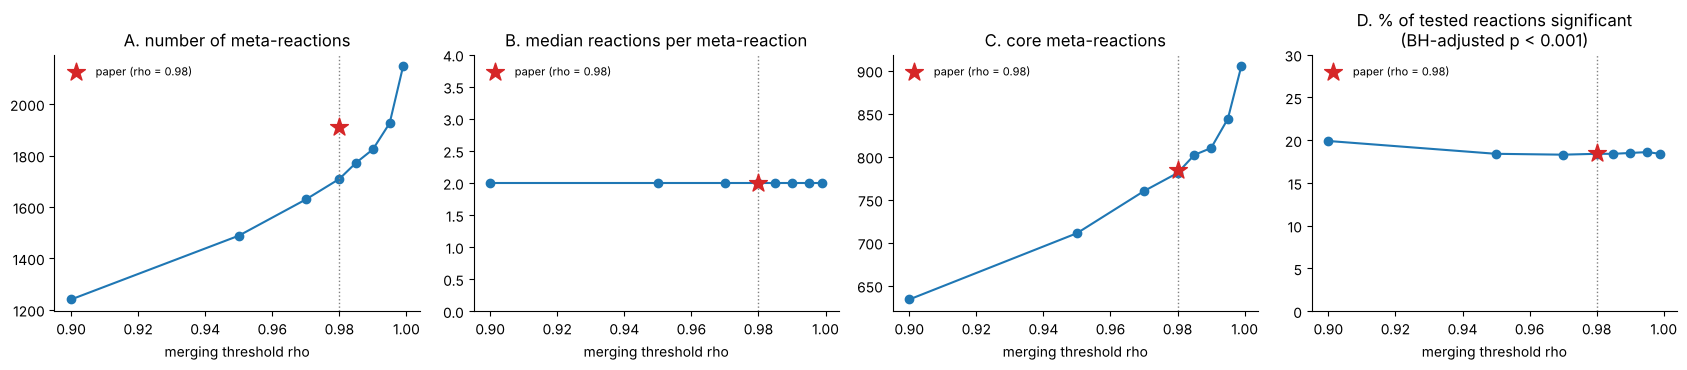

In [14]:
# ---- the paper's chain, re-runnable with ONE threshold changed ------------------------------------------------------------
#  Algorithm 2 / STAR Methods: (1) cluster reactions by Spearman distance, cut at distance 1-rho   -> meta-reactions
#                              (2) average the members' penalties                                  -> one row per meta-reaction
#                              (3) score = -log(1+penalty); drop sens_rows whose score range < epsilon   -> 'tested' meta-reactions
#                              (4) Wilcoxon + Cohen's d + Benjamini-Hochberg on the meta-reactions; members inherit the result
PAPER = {"meta-reactions": 1911, "median size": 2, "core meta-reactions": 784, "reactions tested": 6563, "significant at BH 0.001": 1213}

_TREES = {}
def meta_tree(zero_cutoff=ZERO_CUTOFF):
    """The expensive part (Spearman matrix + complete-linkage tree). Same steps as make_meta_reactions(), but we KEEP the tree,
       so cutting it at many heights is free."""
    if zero_cutoff not in _TREES:
        p = pen.mask(pen <= zero_cutoff, 0.0)
        p = p[(p != 0).all(axis=1)]                              # drop blocked reactions (zero in any cell)
        p = p[(p.max(axis=1) - p.min(axis=1)) != 0]              # drop exactly-constant sens_rows
        rho_m = np.corrcoef(p.rank(axis=1).to_numpy())           # Spearman = Pearson on within-row ranks
        np.fill_diagonal(rho_m, 1.0); rho_m = (rho_m + rho_m.T) / 2
        _TREES[zero_cutoff] = (p, linkage(squareform(1 - rho_m, checks=False), method="complete"))
    return _TREES[zero_cutoff]

def run_chain(rho=0.98, min_range=MIN_RANGE, zero_cutoff=ZERO_CUTOFF):
    p, Z = meta_tree(zero_cutoff)
    lab = pd.Series(fcluster(Z, t=round(1 - rho, 10), criterion="distance"), index=p.index)      # reaction -> meta-reaction
    sizes = lab.value_counts()
    ms = penalties_to_scores(p.groupby(lab).mean(), min_range)                                    # steps 2-3
    res = differential_activity(ms, cells_p, cells_n)                                             # step 4 (BH over the meta-reactions)
    members = lab[lab.isin(ms.index)]                                                             # reactions that inherit a result
    adj = members.map(res.adj_p)
    core = pd.Series([bool(rxn_md.is_core.get(base_id(r), False)) for r in members.index], index=members.index)
    out = {"meta-reactions": len(sizes), "median size": sizes.median(), "singletons": (sizes == 1).mean(),
           "meta tested": len(ms), "core meta-reactions": int(core.groupby(members).any().sum()), "reactions tested": len(members),
           "significant at BH 0.001": int((adj < ALPHA_STRICT).sum()), "significant at BH 0.1": int((adj < ALPHA_LOOSE).sum())}
    return out, sizes, res, members

# consistency check: with the paper's settings the chain must reproduce section 6.2 exactly
sens_chk, _, _, _ = run_chain()
sens_same = (sens_chk["reactions tested"] == len(W)) and (sens_chk["significant at BH 0.001"] == n_sig_strict) and (sens_chk["core meta-reactions"] == len(core_meta_ids))
print(f"chain with the paper's settings reproduces section 6.2 (tested reactions, core meta-reactions, significant): {sens_same}")
assert sens_same, "the re-run chain differs from section 6.2 - do not trust the sweeps below"

# ---- sweep 1: the meta-reaction merging threshold rho (paper: 0.98) ----------------------------------------------------------
RHOS = [0.90, 0.95, 0.97, 0.98, 0.985, 0.99, 0.995, 0.999]
sens_rows = []
for r_ in RHOS:
    o, _, _, _ = run_chain(rho=r_)
    sens_rows.append({"rho": r_, **o})
sens_rho = pd.DataFrame(sens_rows).set_index("rho")
sens_rho["% significant (BH<0.001)"] = (100 * sens_rho["significant at BH 0.001"] / sens_rho["reactions tested"]).round(1)
sens_rho["% significant (BH<0.1)"]   = (100 * sens_rho["significant at BH 0.1"] / sens_rho["reactions tested"]).round(1)
sens_rho["singletons"] = (100 * sens_rho["singletons"]).round(0)
sens_paper_row = pd.DataFrame([{**{k: v for k, v in PAPER.items()}, "% significant (BH<0.001)": round(100 * 1213 / 6563, 1)}], index=["paper (0.98)"])
sens_show = pd.concat([sens_rho[["meta-reactions", "median size", "singletons", "core meta-reactions", "reactions tested",
                              "significant at BH 0.001", "% significant (BH<0.001)", "% significant (BH<0.1)"]], sens_paper_row])
display(sens_show)

# which rho would give the paper's 1,911 meta-reactions? (fine scan; sens_counts only, so it is instantaneous)
_, sens_Z98 = meta_tree()
sens_grid = np.round(np.arange(0.950, 0.9996, 0.0005), 4)
sens_counts = np.array([len(np.unique(fcluster(sens_Z98, t=round(1 - r_, 10), criterion="distance"))) for r_ in sens_grid])
sens_best = sens_grid[np.argmin(np.abs(sens_counts - PAPER["meta-reactions"]))]
print(f"[Inference] the merging threshold that would give a meta-reaction count closest to the paper's 1,911 is rho ~ {sens_best} "
      f"(count {sens_counts[np.argmin(np.abs(sens_counts - PAPER['meta-reactions']))]:,}); the paper states rho = 0.98 (-> {sens_rho.loc[0.98, 'meta-reactions']:,} here).")

fig, ax = plt.subplots(1, 4, figsize=(17, 3.8))
def sens_panel(a, col, title, paper_val=None, fmt=None):
    a.plot(sens_rho.index, sens_rho[col], "o-", color="tab:blue"); a.axvline(0.98, color="grey", ls=":", lw=1)
    if paper_val is not None: a.scatter([0.98], [paper_val], marker="*", s=180, color="tab:red", zorder=5, label="paper (rho = 0.98)")
    a.set_title(title); a.set_xlabel("merging threshold rho"); a.legend(frameon=False, fontsize=8)
sens_panel(ax[0], "meta-reactions", "A. number of meta-reactions", PAPER["meta-reactions"])
sens_panel(ax[1], "median size", "B. median reactions per meta-reaction", PAPER["median size"]); ax[1].set_ylim(0, 4)
sens_panel(ax[2], "core meta-reactions", "C. core meta-reactions", PAPER["core meta-reactions"])
sens_panel(ax[3], "% significant (BH<0.001)", "D. % of tested reactions significant\n(BH-adjusted p < 0.001)", 100 * 1213 / 6563); ax[3].set_ylim(0, 30)
plt.tight_layout(); plt.show()

**How to read sweep 1 (table and four panels).** Each dot is one run of the chain with a different merging threshold ρ; the red star is the paper's number at its own ρ = 0.98 (dotted vertical line).
* **A and C — the number of meta-reactions rises steeply as ρ gets stricter** (merging only near-perfectly correlated reactions leaves more, smaller groups). At the paper's ρ = 0.98 we get 1,709 meta-reactions (paper: 1,911) and 781 core ones (paper: 784).
* **[Inference] ρ alone does not explain the gap.** A count of about 1,911 appears near ρ ≈ 0.9945 (printed under the table) — but by then the core count is already 810–844 (rows ρ = 0.99 and 0.995), above the paper's 784, whereas at 0.98 it matches. The two paper numbers cannot both be reproduced by moving ρ, so the difference more likely lies in *which reactions enter the clustering* (6,385 here; the paper tests at least 6,563) than in the threshold.
* **B — the median size is 2 at every ρ**, so the paper's "median of two reactions per meta-reaction" does not pin ρ down.
* **D — the share of significant reactions barely moves** (18.3–18.6 % for every ρ ≥ 0.95; the coarsest merge, 0.90, gives 19.9 %), against the paper's 18.5 %. The headline fraction is robust to this threshold.

In [15]:
# ---- sweep 2: epsilon, the "constant row" filter (paper Algorithm 2, step 14: scores whose range is below 1e-3 are removed) --------
EPS = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
sens_rows = []
for e in EPS:
    o, _, _, _ = run_chain(min_range=e)
    sens_rows.append({"epsilon": f"{e:g}" + ("  (paper)" if e == MIN_RANGE else ""), "reactions tested": o["reactions tested"], "meta-reactions tested": o["meta tested"],
                 "significant at BH 0.001": o["significant at BH 0.001"], "% significant (BH<0.001)": round(100 * o["significant at BH 0.001"] / o["reactions tested"], 1)})
sens_rows.append({"epsilon": "paper's numbers", "reactions tested": PAPER["reactions tested"], "meta-reactions tested": np.nan,
             "significant at BH 0.001": PAPER["significant at BH 0.001"], "% significant (BH<0.001)": round(100 * 1213 / 6563, 1)})
display(pd.DataFrame(sens_rows).set_index("epsilon"))

# ---- the zero cut-off of the repo notebook (penalties <= 1e-4 are set to 0 before clustering) -----------------------------------
sens_nz = pen[(pen != 0).any(axis=1)]
print(f"smallest non-zero penalty in the whole table: {pen.values[pen.values > 0].min():.3g}")
print("reactions that a zero cut-off c would turn into 'blocked' (any penalty <= c in some cell, excluding reactions that are 0 everywhere):")
print("   " + "   ".join(f"c={c:g}: {int((sens_nz.min(axis=1) <= c).sum())}" for c in [0, 1e-6, 1e-4, 1e-2, 1e-1]))
print("-> the cut-off never triggers on this table, so it cannot matter here (it is a safety net for numerical noise).")

# ---- sweep 3: the significance threshold alpha (paper: 0.001 for the headline count, 0.1 for 'differentially active') ----------
_, _, sens_res, sens_members = run_chain()                                         # the paper's settings
sens_W = sens_members.to_frame("meta").join(sens_res, on="meta")                       # one row per tested reaction, with its meta-reaction's result
ALPHAS = [1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 0.05, 0.1]
sens_alpha_tab = pd.DataFrame({"alpha (BH-adjusted p <)": ALPHAS})
sens_alpha_tab["reactions significant"] = [int((sens_W.adj_p < a).sum()) for a in ALPHAS]
sens_alpha_tab["% of tested"] = (100 * sens_alpha_tab["reactions significant"] / len(sens_W)).round(1)
sens_alpha_tab["... higher in Th17p"] = [f"{(sens_W.loc[sens_W.adj_p < a, 'cohens_d'] > 0).mean():.0%}" for a in ALPHAS]
sens_alpha_tab["median |Cohen's d| of those"] = [round(sens_W.loc[sens_W.adj_p < a, "cohens_d"].abs().median(), 2) for a in ALPHAS]
display(sens_alpha_tab.set_index("alpha (BH-adjusted p <)"))
print(f"paper: 1,213 / 6,563 = {100 * 1213 / 6563:.1f}% at alpha = 0.001;  ours: {int((sens_W.adj_p < 0.001).sum()):,} / {len(sens_W):,} = "
      f"{100 * (sens_W.adj_p < 0.001).mean():.1f}%.   (alpha = 0.1 is the paper's definition of 'differentially active'; it gives no count in the text.)")

,reactions tested,meta-reactions tested,significant at BH 0.001,% significant (BH<0.001)
epsilon,,,,
1e-05,6385,1709.0,1172,18.4
0.0001,6384,1708.0,1172,18.4
0.001 (paper),6361,1706.0,1172,18.4
0.01,6310,1699.0,1163,18.4
0.1,5873,1595.0,1091,18.6
paper's numbers,6563,NaN,1213,18.5


smallest non-zero penalty in the whole table: 2.13
reactions that a zero cut-off c would turn into 'blocked' (any penalty <= c in some cell, excluding reactions that are 0 everywhere):
   c=0: 0   c=1e-06: 0   c=0.0001: 0   c=0.01: 0   c=0.1: 0
-> the cut-off never triggers on this table, so it cannot matter here (it is a safety net for numerical noise).


,reactions significant,% of tested,... higher in Th17p,median |Cohen's d| of those
alpha (BH-adjusted p <),,,,
1.0000e-06,299,4.7,71%,0.68
1.0000e-05,539,8.5,78%,0.62
1.0000e-04,836,13.1,75%,0.60
1.0000e-03,1172,18.4,78%,0.55
1.0000e-02,1979,31.1,72%,0.45
5.0000e-02,2639,41.5,72%,0.39
1.0000e-01,3272,51.4,69%,0.35


paper: 1,213 / 6,563 = 18.5% at alpha = 0.001;  ours: 1,172 / 6,361 = 18.4%.   (alpha = 0.1 is the paper's definition of 'differentially active'; it gives no count in the text.)


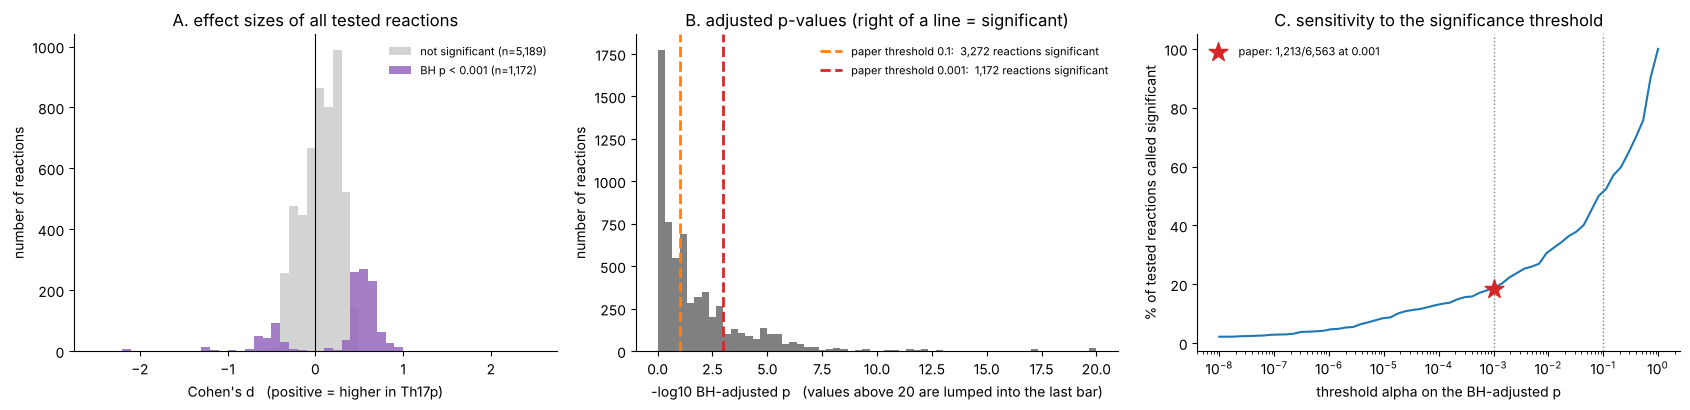

median |Cohen's d|:  significant reactions (BH<0.001) 0.55   vs   the others 0.17


In [16]:
# ---- the histograms ----------------------------------------------------------------------------------------------------------
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
sens_sig = sens_W.adj_p < ALPHA_STRICT
sens_bins = np.linspace(-2.5, 2.5, 51)
ax[0].hist(sens_W.cohens_d[~sens_sig].clip(-2.5, 2.5), bins=sens_bins, color="lightgrey", label=f"not significant (n={int((~sens_sig).sum()):,})")
ax[0].hist(sens_W.cohens_d[sens_sig].clip(-2.5, 2.5), bins=sens_bins, color="tab:purple", alpha=.85, label=f"BH p < 0.001 (n={int(sens_sig.sum()):,})")
ax[0].axvline(0, color="k", lw=.8); ax[0].set_xlabel("Cohen's d   (positive = higher in Th17p)"); ax[0].set_ylabel("number of reactions")
ax[0].set_title("A. effect sizes of all tested reactions"); ax[0].legend(frameon=False, fontsize=8)

sens_lp = -np.log10(sens_W.adj_p.clip(lower=1e-30))
ax[1].hist(sens_lp.clip(upper=20), bins=np.linspace(0, 20, 61), color="grey")
for a, col in [(ALPHA_LOOSE, "tab:orange"), (ALPHA_STRICT, "tab:red")]:
    ax[1].axvline(-np.log10(a), color=col, ls="--", lw=2, label=f"paper threshold {a:g}:  {int((sens_W.adj_p < a).sum()):,} reactions significant")
ax[1].set_xlabel("-log10 BH-adjusted p   (values above 20 are lumped into the last bar)"); ax[1].set_ylabel("number of reactions")
ax[1].set_title("B. adjusted p-values (right of a line = significant)"); ax[1].legend(frameon=False, fontsize=8)

sens_grid_a = np.logspace(-8, 0, 60)
ax[2].semilogx(sens_grid_a, [100 * (sens_W.adj_p < a).mean() for a in sens_grid_a], color="tab:blue")
ax[2].scatter([0.001], [100 * 1213 / 6563], marker="*", s=200, color="tab:red", zorder=5, label="paper: 1,213/6,563 at 0.001")
ax[2].axvline(0.001, color="grey", ls=":", lw=1); ax[2].axvline(0.1, color="grey", ls=":", lw=1)
ax[2].set_xlabel("threshold alpha on the BH-adjusted p"); ax[2].set_ylabel("% of tested reactions called significant")
ax[2].set_title("C. sensitivity to the significance threshold"); ax[2].legend(frameon=False, fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()
print(f"median |Cohen's d|:  significant reactions (BH<0.001) {sens_W.cohens_d[sens_sig].abs().median():.2f}   vs   the others {sens_W.cohens_d[~sens_sig].abs().median():.2f}")

**How to read sweeps 2 and 3 and the histograms.**
* **ε (sweep 2).** Values up to 10⁻³ hardly change anything (6,385 → 6,361 tested reactions); 0.1 removes about 500. **No ε reaches the paper's 6,563 tested reactions:** only 6,385 reactions have a non-zero score that also *varies* between cells (6,797 are non-zero; the other 412 are constant). **[Inference]** The paper's table was computed from a slightly different set of reactions (another Recon2 export or software version), not with a different ε. The *share* significant stays at 18.4–18.6 % throughout (paper: 18.5 %).
* **Zero cut-off.** It never triggers: the smallest non-zero penalty in the whole table is 2.13, so no reaction would be turned into "blocked". It is a safety net for numerical noise, not a tuning knob here.
* **α (sweep 3, panels B and C).** At the paper's headline threshold 0.001 we call 1,172 of 6,361 reactions significant (18.4 %) against the paper's 1,213 of 6,563 (18.5 %). At the paper's looser definition of "differentially active" (adjusted p < 0.1) about half of all tested reactions qualify (51.4 %) — a lenient bar, and one more reason to look at effect size. Moving α changes *how many*, not *which direction*: between 69 % and 78 % of the significant reactions are higher in Th17p at every α, and the median |d| of the significant reactions falls from 0.68 (α = 10⁻⁶) to 0.35 (α = 0.1) as the bar is lowered.
* **Panel A** shows why: the significant reactions (purple) sit in the tails of the effect-size histogram; their median |d| is 0.55 against 0.17 for the others (printed under the figure).

### 6.3 Figure 2B — PCA of the Compass space (core meta-reactions)
**What the paper does.** Treat each cell as a vector of *meta-reaction scores* (restricted to the 784 core ones) and run PCA — a "metabolic" analogue of the usual transcriptome PCA **[Paper, Results; Fig. 2B]**. They report PC1 ↔ total metabolic activity and late-differentiation signature, and PC2/PC3 ↔ glycolysis vs fatty-acid oxidation and pathogenicity markers.
**[Inference — a choice the paper does not specify]** whether each meta-reaction is standardised (z-scored) before PCA. We compute **both**: *unscaled* (scikit-learn default; high-variance reactions dominate) and *scaled* (every meta-reaction counts equally), and use the scaled one downstream.

share of total variance carried by the 10 highest-variance meta-reactions (unscaled): 34%


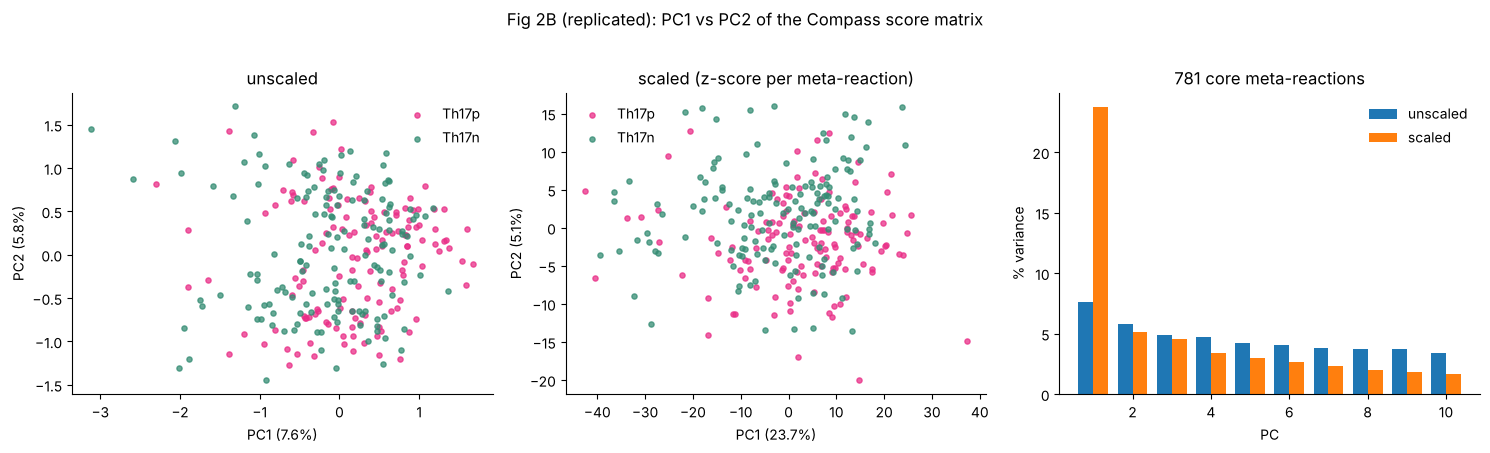

,PCA,PC,variance,Pearson r with total metab. activity,Spearman rho with pathogenicity score,AUC (Th17p higher on PC)
0,unscaled,PC1,7.6%,0.34,0.13,0.62
1,unscaled,PC2,5.8%,-0.02,-0.02,0.46
2,unscaled,PC3,4.9%,-0.02,-0.17,0.33
3,scaled (z-score per meta-reaction),PC1,23.7%,0.33,0.13,0.61
4,scaled (z-score per meta-reaction),PC2,5.1%,0.05,-0.30,0.33
5,scaled (z-score per meta-reaction),PC3,4.6%,0.02,-0.14,0.40


In [17]:
X0 = meta_scores.loc[core_meta_ids].T                                     # cells x core meta-reactions
modes = {"unscaled": X0, "scaled (z-score per meta-reaction)": (X0 - X0.mean()) / X0.std()}
is_p = (meta.cell_type[X0.index] == "Th17p").to_numpy()

fits, rows = {}, []
for name, Xm in modes.items():
    p_ = PCA(n_components=10).fit(Xm.to_numpy())
    pc_ = pd.DataFrame(p_.transform(Xm.to_numpy()), index=Xm.index, columns=[f"PC{i+1}" for i in range(10)])
    fits[name] = (p_, pc_)
    for k in range(3):
        v = pc_.iloc[:, k]
        auc = stats.mannwhitneyu(v[is_p], v[~is_p]).statistic / (is_p.sum() * (~is_p).sum())
        rows.append((name, f"PC{k+1}", f"{p_.explained_variance_ratio_[k]:.1%}", round(stats.pearsonr(tma[v.index], v)[0], 2),
                     round(stats.spearmanr(pathogenicity[v.index], v)[0], 2), round(auc, 2)))
print("share of total variance carried by the 10 highest-variance meta-reactions (unscaled):",
      f"{(X0.var().sort_values(ascending=False).head(10).sum() / X0.var().sum()):.0%}")

fig, ax = plt.subplots(1, 3, figsize=(15, 4.4))
for a_, (name, (p_, pc_)) in zip(ax[:2], fits.items()):
    for g, c in PAL.items():
        m = (meta.cell_type[pc_.index] == g).to_numpy(); a_.scatter(pc_["PC1"][m], pc_["PC2"][m], s=14, color=c, alpha=.75, label=g)
    a_.set_xlabel(f"PC1 ({p_.explained_variance_ratio_[0]:.1%})"); a_.set_ylabel(f"PC2 ({p_.explained_variance_ratio_[1]:.1%})"); a_.set_title(name); a_.legend(frameon=False)
for i, (name, (p_, _)) in enumerate(fits.items()):
    ax[2].bar(np.arange(1, 11) + (i - .5) * .38, p_.explained_variance_ratio_ * 100, width=.38, label=name.split(" ")[0])
ax[2].set_xlabel("PC"); ax[2].set_ylabel("% variance"); ax[2].set_title(f"{len(core_meta_ids)} core meta-reactions"); ax[2].legend(frameon=False)
plt.suptitle("Fig 2B (replicated): PC1 vs PC2 of the Compass score matrix", y=1.02); plt.tight_layout(); plt.show()

pd.DataFrame(rows, columns=["PCA", "PC", "variance", "Pearson r with total metab. activity", "Spearman rho with pathogenicity score", "AUC (Th17p higher on PC)"])

**How to read it.** Each dot is a *cell* positioned by its overall metabolic profile. The table answers three questions per PC: how much variance it carries, whether it tracks total metabolic activity (§3.5), and whether it separates the groups (AUC 0.5 = not at all; far from 0.5 in either direction = separation). **Compare with §3.4:** on the transcriptome the two conditions form two distinct clouds, whereas in the *metabolic* space they overlap heavily — the differences Compass reports are many *small, coordinated shifts* (typical |Cohen's d| 0.3–0.6), not two different metabolic worlds. That is an important calibration for how strongly to word any "metabolic state" claim **[Inference from these numbers]**.

In [18]:
# loadings of the SCALED PCA: which meta-reactions define PC1 and PC2?
p_s, pcs = fits["scaled (z-score per meta-reaction)"]
ev = p_s.explained_variance_ratio_

def describe_meta(mid):
    members = labels_meta.index[labels_meta == mid]
    core_members = [m for m in members if rxn_md.is_core.get(base_id(m), False)] or list(members)
    first = base_id(core_members[0])
    return f"{rxn_md.reaction_name[first][:48]} [{rxn_md.subsystem[first][:28]}]" + (f" (+{len(members)-1} more)" if len(members) > 1 else "")

load = pd.DataFrame(p_s.components_[:3].T, index=core_meta_ids, columns=["PC1", "PC2", "PC3"])
tops = []
for pc in ["PC1", "PC2"]:
    for sign, name in [(1, "positive"), (-1, "negative")]:
        t = (load[pc] * sign).sort_values(ascending=False).head(4)
        tops += [(pc, name, describe_meta(m), round(v * sign, 3)) for m, v in t.items()]
pd.DataFrame(tops, columns=["PC", "direction", "top-loading meta-reaction (scaled PCA)", "loading"])

,PC,direction,top-loading meta-reaction (scaled PCA),loading
0,PC1,positive,"5-beta-cytochrome P450, family 27, subfamily A...",0.064
1,PC1,positive,Tyrosine:dopa oxidase [Tyrosine metabolism],0.064
2,PC1,positive,L-dopachrome isomerase 1 [Tyrosine metabolism],0.064
3,PC1,positive,Nad(p)h biliverdin reductase [Heme degradation...,0.064
4,PC1,negative,UDPglucose pyrophosphohydrolase Pyrimidine met...,-0.010
5,PC1,negative,"NAD nucleosidase,extracellular [NAD metabolism...",-0.007
6,PC1,negative,Glycerone phosphate phosphohydrolase (alkaline...,-0.006
7,PC1,negative,Nitric Oxide Synthase (intermediate forming) [...,-0.005
8,PC2,positive,"acyl-CoA oxidase (hexadecanoyl-CoA), peroxisom...",0.102
9,PC2,positive,trans-Hexadec-2-enoyl-CoA reductase Fatty acid...,0.099


**What the loadings say (scaled PCA).** PC1 carries ≈ 24 % of the variance and its top loadings are *all equal* (≈ 0.064) across many unrelated reactions — it is a shared "overall level" axis, which is why it tracks total metabolic activity (§6.4) rather than one pathway. PC2 is led by **fatty-acid oxidation / carnitine-shuttle** meta-reactions on one side and **purine / pentose-phosphate** reactions on the other, and Th17p sit lower on it (AUC ≈ 0.33; Spearman −0.30 with the pathogenicity score) — in line with the paper's description of PC2/PC3 as a choice between aerobic glycolysis and fatty-acid oxidation that correlates with pathogenicity markers **[Paper, Results "Th17 functional states are associated with metabolic states"]**. The unscaled PCA does not show this clearly, so the scaling choice matters.

### 6.4 Figure S2C (left) — PC1 vs "total metabolic activity"
**Paper claim:** PC1 correlates with the cell's total metabolic activity — Pearson ρ = 0.36 (p < 4e-10) *after controlling* for the denominator (sum expression of all protein-coding genes), 0.56 without controlling **[Paper, Results & STAR Methods]**. The companion panel (late-stage Th17 differentiation signature) needs Yosef et al. 2013 microarray data, which is **not** in the repo or paper → not replicated here.

Pearson(total metabolic activity, PC1)               = 0.33  (p=1e-08)   paper: 0.56
partial, controlling for the denominator             = 0.40  (p=2e-12)   paper: 0.36


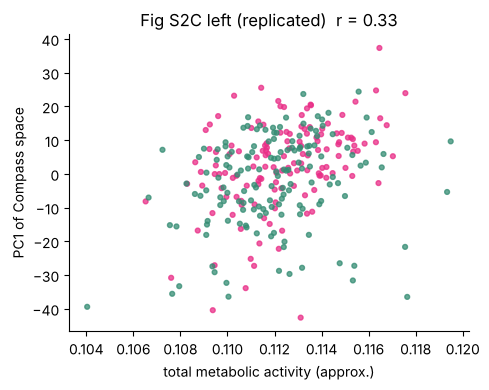

In [19]:
def partial_corr(x, y, covar):
    """Pearson correlation of x and y after regressing `covar` out of both (residual method)."""
    x, y, c = map(np.asarray, (x, y, covar))
    rx = x - np.polyval(np.polyfit(c, x, 1), c); ry = y - np.polyval(np.polyfit(c, y, 1), c)
    r = np.corrcoef(rx, ry)[0, 1]; n = len(x)
    t = r * np.sqrt((n - 3) / (1 - r**2))
    return r, 2 * stats.t.sf(abs(t), n - 3)

x = tma[pcs.index]; y = pcs["PC1"]
r_raw, p_raw = stats.pearsonr(x, y)
r_par, p_par = partial_corr(x, y, denominator[pcs.index])
print(f"Pearson(total metabolic activity, PC1)               = {r_raw:.2f}  (p={p_raw:.1g})   paper: 0.56")
print(f"partial, controlling for the denominator             = {r_par:.2f}  (p={p_par:.1g})   paper: 0.36")

fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(x, y, c=meta.cell_type[pcs.index].map(PAL), s=12, alpha=.75)
ax.set_xlabel("total metabolic activity (approx.)"); ax.set_ylabel("PC1 of Compass space"); ax.set_title(f"Fig S2C left (replicated)  r = {r_raw:.2f}")
plt.tight_layout(); plt.show()

**How to read it.** A positive correlation says PC1 is partly "how much of this cell's transcriptome is metabolic enzymes" — a *global expression-level* effect rather than a specific pathway. **Honest status: this panel does not replicate numerically.** The sign and significance agree with the paper, but our raw correlation is *lower* and our partial correlation *higher* than the paper's (the paper's ordering is 0.56 raw > 0.36 partial; ours is reversed). Likely reasons **[Inference]**: (i) our denominator is every gene in the gene-filtered repo matrix, not the protein-coding set; (ii) the PCA scaling choice (§6.3); (iii) the paper's PC1 is computed from a slightly different meta-reaction set. Treat this as an open item for the team rather than a result.

#### 6.4b What is PC1, then? (extra check — not in the paper)
**Question.** PC1 is the "overall level" axis (§6.3). The paper links it to total metabolic activity. Is it equally well explained by simple, *technical* properties of a cell — how many genes it detected, how deeply it was sequenced?
**How.** Spearman correlation (rank-based, robust to outliers) between each cell's PC1 coordinate and several per-cell variables. A high |ρ| means PC1 largely re-expresses that variable.

In [20]:
n_metab_detected = (expr[is_metab] > 0).sum()                    # metabolic genes with TPM > 0, per cell
cand = {
    "total metabolic activity (approx., §3.5)": tma,
    "genes detected per cell (all genes)":      n_detected,
    "metabolic genes detected per cell":        n_metab_detected,
    "sequencing depth (NREADS)":                meta["NREADS"],
    "alignment rate (RALIGN)":                  meta["RALIGN"],
    "pathogenicity score (§3.3)":               pathogenicity,
}
tab = pd.DataFrame({k: [stats.spearmanr(v[pcs.index], pcs["PC1"])[0]] for k, v in cand.items()},
                   index=["Spearman with PC1"]).T.round(2)
display(tab)
print("(PC1 is the sign-arbitrary axis of the scaled PCA; read |rho| and compare rows, not the sign of the whole column.)")

,Spearman with PC1
"total metabolic activity (approx., §3.5)",0.35
genes detected per cell (all genes),0.52
metabolic genes detected per cell,0.57
sequencing depth (NREADS),0.14
alignment rate (RALIGN),0.05
pathogenicity score (§3.3),0.13


(PC1 is the sign-arbitrary axis of the scaled PCA; read |rho| and compare rows, not the sign of the whole column.)


**What you should see.** PC1 correlates more strongly with the *number of metabolic genes detected* in a cell (ρ ≈ 0.57) and with the number of genes detected overall (ρ ≈ 0.52) than with total metabolic activity (ρ ≈ 0.35); it is only weakly related to sequencing depth (≈ 0.14), alignment rate (≈ 0.05) and the pathogenicity score (≈ 0.13).

**How to read it [Inference].** "PC1 = metabolic state" is therefore only one of two readings. PC1 may equally be a **detection / library-complexity axis**: a cell in which more enzyme genes happen to be captured has fewer reactions at the maximum penalty and so gets uniformly higher potential activity across hundreds of unrelated reactions (§5, Notebook 2 Part C). This does not contradict the paper's statement (more detected metabolic genes also means a higher total metabolic activity), but it means the PC1 axis alone is not evidence of *biological* metabolic reprogramming. A natural control — remove the effect of the detection count from the scores before testing the groups — is listed as a candidate extension in the weekly update.

### 6.5 Figure 2C — which reactions differ between Th17p and Th17n, by pathway
**What the paper shows.** For selected pathways (glycolysis, TCA cycle, amino-acid metabolism, fatty-acid oxidation), each dot is a reaction: x = Cohen's d (positive = higher in Th17p), y = −log10 BH-adjusted Wilcoxon p; labelled dots are the reactions discussed in the text **[Paper, Fig. 2C; Repo postprocessing.ipynb "Figure 2C replication"]**. Only **core** reactions are shown; TCA reactions outside the mitochondrion are relabelled "Other" **[Repo]**.

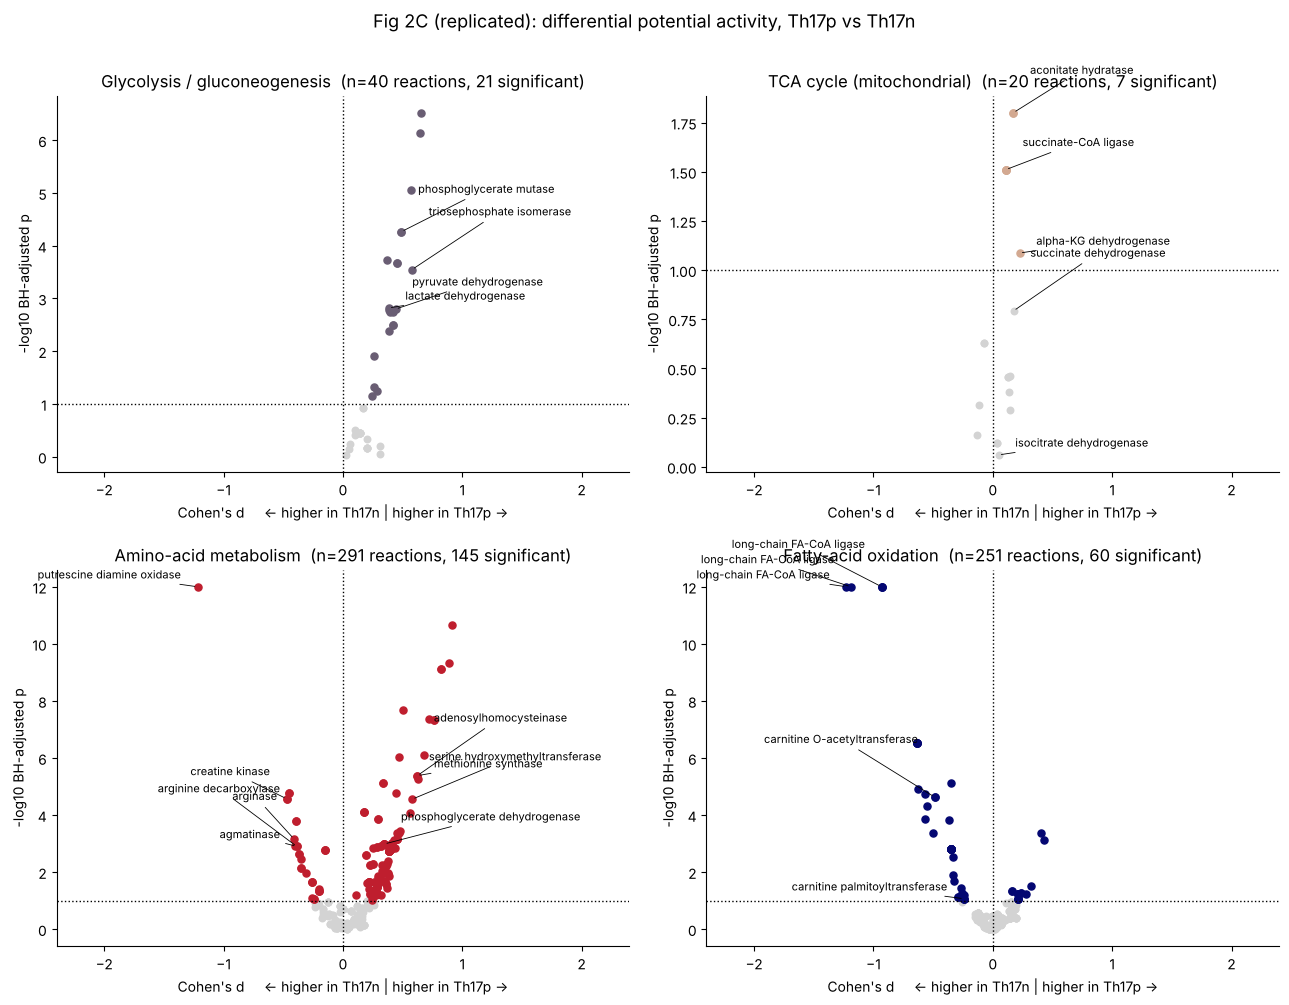

,reaction_name,subsystem,cohens_d,adj_p,label
FACOAL1821_neg,fatty-acid--CoA ligase,Fatty acid oxidation,-1.2264,0.0000,long-chain FA-CoA ligase
r0281_neg,Putrescine:oxygen oxidoreductase (deaminating)...,Methionine and cysteine metabolism,-1.2178,0.0000,putrescine diamine oxidase
r1257_pos,EC:6.2.1.3,Fatty acid oxidation,-1.1896,0.0000,long-chain FA-CoA ligase
FACOAL1831_neg,fatty-acid--CoA ligase,Fatty acid oxidation,-0.9312,0.0000,long-chain FA-CoA ligase
CSNATr_neg,carnitine O-acetyltransferase,Fatty acid oxidation,-0.4873,0.0000,carnitine O-acetyltransferase
CK_pos,ATP Creatine kinase,Urea cycle,-0.4719,0.0000,creatine kinase
ARGN_pos,arginase,Urea cycle,-0.4116,0.0007,arginase
AGMTm_pos,agmatinase (m),Arginine and Proline Metabolism,-0.3870,0.0013,agmatinase
ARGDCm_pos,arginine decarboxylase (m),Arginine and Proline Metabolism,-0.3870,0.0013,arginine decarboxylase
C160CPT1_pos,production of Palmitoylcarnitine,Fatty acid oxidation,-0.2415,0.0859,carnitine palmitoyltransferase


In [21]:
LABELED = {   # [Repo compass_analysis.py `labeled_reactions`] reactions the authors annotate in Fig. 2C
    "PGM_neg": "phosphoglycerate mutase", "LDH_L_neg": "lactate dehydrogenase", "PDHm_pos": "pyruvate dehydrogenase",
    "TPI_neg": "triosephosphate isomerase", "FACOAL1821_neg": "long-chain FA-CoA ligase", "r1257_pos": "long-chain FA-CoA ligase",
    "FACOAL1831_neg": "long-chain FA-CoA ligase", "CSNATr_neg": "carnitine O-acetyltransferase", "C160CPT1_pos": "carnitine palmitoyltransferase",
    "ACONTm_pos": "aconitate hydratase", "SUCOASm_pos": "succinate-CoA ligase", "AKGDm_pos": "alpha-KG dehydrogenase",
    "SUCD1m_pos": "succinate dehydrogenase", "ICDHyrm_pos": "isocitrate dehydrogenase", "CK_pos": "creatine kinase",
    "PGCD_pos": "phosphoglycerate dehydrogenase", "ARGSS_pos": "arginosuccinate synthase", "r0281_neg": "putrescine diamine oxidase",
    "SPMDOX_pos": "spermidine dehydrogenase", "ARGDCm_pos": "arginine decarboxylase", "AGMTm_pos": "agmatinase",
    "GHMT2r_pos": "serine hydroxymethyltransferase", "AHC_pos": "adenosylhomocysteinase", "METAT_pos": "methionine adenosyltransferase",
    "METS_pos": "methionine synthase", "ARGN_pos": "arginase",
}
AMINO_ACID = ["Alanine and aspartate metabolism", "Arginine and Proline Metabolism", "beta-Alanine metabolism", "Cysteine Metabolism",
              "D-alanine metabolism", "Folate metabolism", "Glutamate metabolism", "Glycine, serine, alanine and threonine metabolism",
              "Histidine metabolism", "Lysine metabolism", "Methionine and cysteine metabolism", "Taurine and hypotaurine metabolism",
              "Tryptophan metabolism", "Tyrosine metabolism", "Urea cycle", "Valine, leucine, and isoleucine metabolism"]   # [Repo]

panels = [("Glycolysis / gluconeogenesis", Wc[Wc.subsystem == "Glycolysis/gluconeogenesis"], "#695D73"),
          ("TCA cycle (mitochondrial)",     Wc[Wc.subsystem == "Citric acid cycle"],          "#D3A991"),
          ("Amino-acid metabolism",         Wc[Wc.subsystem.isin(AMINO_ACID)],                "#BF1E2E"),
          ("Fatty-acid oxidation",          Wc[Wc.subsystem == "Fatty acid oxidation"],       "#040772")]

fig, axes = plt.subplots(2, 2, figsize=(13, 10)); axes = axes.ravel()
for ax, (title, d, col) in zip(axes, panels):
    y = -np.log10(d.adj_p.clip(lower=1e-12))
    sig = d.adj_p < ALPHA_LOOSE
    ax.scatter(d.cohens_d[~sig], y[~sig], s=22, color="lightgrey"); ax.scatter(d.cohens_d[sig], y[sig], s=26, color=col)
    ax.axvline(0, color="k", ls=":", lw=1); ax.axhline(-np.log10(ALPHA_LOOSE), color="k", ls=":", lw=1)
    for k, r in enumerate(d.loc[d.index.intersection(LABELED)].sort_values("cohens_d").index):
        right = d.cohens_d[r] >= 0
        ax.annotate(LABELED[r], (d.cohens_d[r], y[r]), xytext=(12 if right else -12, 6 + 11 * (k % 4)), textcoords="offset points",
                    ha="left" if right else "right", fontsize=8, arrowprops=dict(arrowstyle="-", lw=.6))
    ax.set_xlim(-2.4, 2.4); ax.set_title(f"{title}  (n={len(d)} reactions, {int(sig.sum())} significant)")
    ax.set_xlabel("Cohen's d     <- higher in Th17n | higher in Th17p ->"); ax.set_ylabel("-log10 BH-adjusted p")
plt.suptitle("Fig 2C (replicated): differential potential activity, Th17p vs Th17n", y=1.0, fontsize=13)
plt.tight_layout(); plt.show()

focus = Wc.loc[Wc.index.intersection(LABELED), ["reaction_name", "subsystem", "cohens_d", "adj_p"]].sort_values("cohens_d")
focus.assign(label=[LABELED[r] for r in focus.index]).round(4)

**How to read it.** Right of 0 = more potential activity in Th17p; left = more in Th17n; above the dotted horizontal line = significant at BH p < 0.1. The paper's headline reading: glycolytic reactions lean Th17p (right), long-chain fatty-acid activation and CPT lean Th17n (left), and the TCA cycle splits — two segments up in Th17p, not the whole cycle **[Paper, Results "Compass predicts metabolic regulators…" ]**. Compare each panel with that sentence and check the table below the figure for the labelled reactions' signs.

### 6.6 Figure 2E — Cohen's d for every core reaction, by Recon2 subsystem
**What the paper shows and why.** Dots are reactions grouped by pathway, coloured by the sign of Cohen's d. The point: "many classically defined metabolic pathways included *both* reactions predicted to be pro-pathogenic and pro-regulatory — highlighting the value in examining single reactions within a global network rather than conducting a pathway-level analysis" **[Paper, Results]**. Filters follow the repo: drop "Miscellaneous", "Unassigned", transport/exchange, "Other", and subsystems with ≤ 5 reactions.

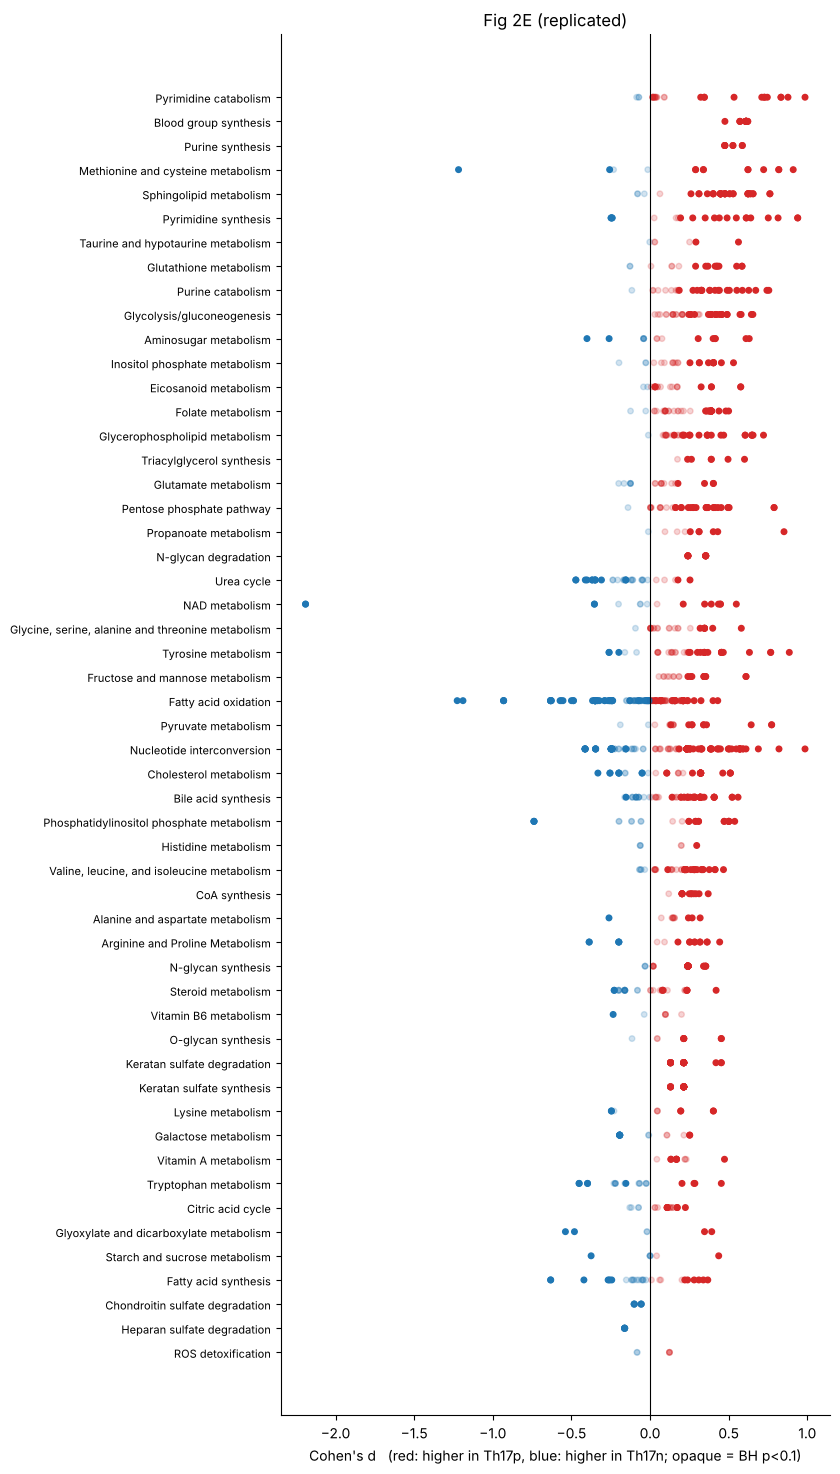

20 of 50 subsystems that contain significant reactions have significant reactions in BOTH directions
but 82% of ALL significant core reactions are higher in Th17p (a global shift, cf. PC1 vs total metabolic activity)


In [22]:
E = Wc[~Wc.subsystem.isin(["Miscellaneous", "Unassigned", "Other"]) & ~Wc.subsystem.str.contains("Transport|Exchange", regex=True, na=False)]
E = E[E.subsystem.map(E.subsystem.value_counts()) > 5]
sig_E = E[E.adj_p < ALPHA_LOOSE]
order_E = sig_E.groupby("subsystem").cohens_d.median().abs().sort_values().index.tolist()
order_E = [s for s in E.subsystem.unique() if s not in order_E] + order_E          # subsystems with no significant reaction go first

fig, ax = plt.subplots(figsize=(8.5, max(6, 0.28 * len(order_E))))
ypos = {s: i for i, s in enumerate(order_E)}
ax.scatter(E.cohens_d, E.subsystem.map(ypos), c=np.where(E.cohens_d >= 0, "tab:red", "tab:blue"), alpha=np.where(E.adj_p < ALPHA_LOOSE, 1.0, 0.2), s=16)
ax.set_yticks(range(len(order_E))); ax.set_yticklabels(order_E, fontsize=8); ax.axvline(0, color="k", lw=.8)
ax.set_xlabel("Cohen's d   (red: higher in Th17p, blue: higher in Th17n; opaque = BH p<0.1)"); ax.set_title("Fig 2E (replicated)")
plt.tight_layout(); plt.show()

both = sig_E.groupby("subsystem").cohens_d.agg(lambda s: (s > 0).any() and (s < 0).any())
print(f"{both.sum()} of {sig_E.subsystem.nunique()} subsystems that contain significant reactions have significant reactions in BOTH directions")
print(f"but {(sig_E.cohens_d > 0).mean():.0%} of ALL significant core reactions are higher in Th17p (a global shift, cf. PC1 vs total metabolic activity)")

**How to read it.** A subsystem row with opaque red *and* blue dots is a pathway where one set of reactions is Th17p-leaning and another Th17n-leaning — the paper's argument for reaction-level (not pathway-level) analysis. Rows with only faint dots show pathways with no significant differences. **Also look at the overall picture [Inference]:** the large majority of significant reactions are red (higher in Th17p). Part of this may be a *global* shift — Th17p cells have more total metabolic-gene signal (§3.5/§6.4) — rather than pathway-specific biology; a natural control for Week 2+ is to repeat the test after regressing out total metabolic activity / library size.

## 7 · Scorecard — how close is the repo's precomputed output to the paper's numbers?

In [23]:
rows = [
 ("Recon2 reactions",                          "7,440",           f"{len(rxn_md):,}",                                   "exact"),
 ("Recon2 unique metabolites",                 "2,626",           f"{met_md['metabolite_no_compartment'].nunique():,}", "exact"),
 ("Th17p / Th17n cells",                       "139 / 151",       f"{len(cells_p)} / {len(cells_n)}",                   "exact"),
 ("Reactions tested (after filtering)",        "6,563",           f"{len(W):,} (via meta-reactions); {len(res_rxn):,} single", "close (-3%)"),
 ("Reactions significant, BH p<0.001",         "1,213 (18.5%)",   f"{n_sig_strict:,} ({n_sig_strict/len(W):.1%})",      "same fraction"),
 ("Meta-reactions",                            "1,911",           f"{len(sizes):,}",                                    "11% fewer (clustering details / filtering)"),
 ("Median reactions per meta-reaction",        "2",               f"{sizes.median():.0f}",                              "exact"),
 ("Core meta-reactions",                       "784",             f"{len(core_meta_ids)}",                              "close"),
 ("Pearson(PC1, total metabolic activity)",    "0.56 (0.36 partial)", f"{r_raw:.2f} ({r_par:.2f} partial)",              "does NOT match; see 6.4"),
]
scorecard = pd.DataFrame(rows, columns=["quantity", "paper", "this notebook", "verdict"])
scorecard

,quantity,paper,this notebook,verdict
0,Recon2 reactions,"7,440","7,440",exact
1,Recon2 unique metabolites,"2,626","2,626",exact
2,Th17p / Th17n cells,139 / 151,139 / 151,exact
3,Reactions tested (after filtering),"6,563","6,361 (via meta-reactions); 6,381 single",close (-3%)
4,"Reactions significant, BH p<0.001","1,213 (18.5%)","1,172 (18.4%)",same fraction
5,Meta-reactions,"1,911","1,709",11% fewer (clustering details / filtering)
6,Median reactions per meta-reaction,2,2,exact
7,Core meta-reactions,784,781,close
8,"Pearson(PC1, total metabolic activity)",0.56 (0.36 partial),0.33 (0.40 partial),does NOT match; see 6.4


**Reading the scorecard.** Close agreement on counts and fractions means (i) we understand the pipeline, and (ii) the repo's precomputed `reactions.tsv` is a faithful version of the paper's output. Differences are expected from: version differences between the 2021 analysis and the current repo; the "tested" set (the paper filters reactions slightly differently from the repo notebook); and our approximate "total metabolic activity" denominator **[Inference]**.

### Save the key tables (opens in Excel with European settings: `;` separator, `,` decimal)

In [24]:
(W.drop(columns=["formula"])
   .sort_values("adj_p")
   .to_csv(OUT / "differential_activity_by_reaction.csv", sep=";", decimal=","))
labels_meta.to_frame().to_csv(OUT / "meta_reaction_membership.csv", sep=";", decimal=",")
scorecard.to_csv(OUT / "scorecard_vs_paper.csv", sep=";", decimal=",", index=False)
print("written:", sorted(p.name for p in OUT.iterdir()))

written: ['differential_activity_by_reaction.csv', 'meta_reaction_membership.csv', 'scorecard_vs_paper.csv']


## 8 · Take-aways (what you should be able to explain after this notebook)
1. **The data:** 290 single cells (139 Th17p, 151 Th17n), Smart-seq TPM, ≈ 5.9 k genes detected per cell, ≈ 1/3 zeros; labels behave as the paper says on an independent 22-gene signature (§3.3).
2. **Compass output:** one penalty per *unidirectional* reaction per cell; ≈ 1/3 of rows are blocked (always 0), a few hundred are near-constant, ≈ 6.4 k carry information (§5).
3. **Statistical unit and caveat:** tests are cell-level; neighbouring cells are deliberately made similar by smoothing → treat p-values as descriptive; prefer Cohen's d (§3.4, §6.2).
4. **Meta-reactions** reduce ≈ 6.4 k correlated reactions to ≈ 1.7 k groups; they are **dataset-dependent** (§6.1).
5. **The headline biology** (glycolysis up / long-chain FA activation + CPT down in Th17p, mixed pathways) can be reproduced from the repo's output without running the optimiser (§6.5–6.6). **But** the transcriptome separates the groups sharply while the metabolic space does not (§3.4 vs §6.3), and most significant reactions point the same way (§6.6) — both are things to probe, not accept.
6. **What the biggest axis of the Compass space is:** PC1 follows how many (metabolic) genes a cell happens to detect at least as much as it follows "total metabolic activity" (§6.4b), and Th17p cells were sequenced about 18 % less deeply than Th17n (§3.1) — so any claim built on the *global* shift needs a detection/depth control **[Inference]**.

**Try next (all within the repo):** change `CLUSTER_HEIGHT` to 0.05 or 0.1 and see how counts and Fig 2C change; compare scaled vs unscaled PCA in §6.3; swap the pathogenicity score for the Th17p/Th17n label in §6.3; look up one labelled reaction's raw penalties across cells (`pen.loc["PGM_neg"]`) and ask *why* it varies — Notebook 2 explains where those numbers come from.